In [193]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
from dataclasses import dataclass
import torchvision.utils as vutils
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score, average_precision_score,f1_score
import networkx as nx
from sklearn.preprocessing import MinMaxScaler,StandardScaler


In [194]:
# model = AERNN(46572, train_X.shape[1], 256 , 8)
# # model.apply(bias_init)
# # model = model.to(device)

# optimizer = torch.optim.RMSprop(model.parameters(), lr=1e-3)
# loss_fn = nn.MSELoss()

In [195]:
# def extract_graph_features(df, G):
#     # Pre-calculate degree dicts for speed
#     degrees = dict(G.degree())
    
#     src_degrees = []
#     tgt_degrees = []
#     common_neighbors = []
    
#     for src, tgt in zip(df['source'], df['target']):
#         src_degrees.append(degrees.get(src, 0))
#         tgt_degrees.append(degrees.get(tgt, 0))
        
#         # Intersection of neighbors
#         if G.has_node(src) and G.has_node(tgt):
#             cn = len(list(set(G.successors(src)) & set(G.successors(tgt))))        
#         else:
#             cn = 0
#         common_neighbors.append(cn)
        
#     df['src_degree'] = src_degrees
#     df['tgt_degree'] = tgt_degrees
#     df['common_neighbors'] = common_neighbors
#     return df

In [196]:
def extract_graph_features(df, G):
    # Pre-calculate degree dicts
    degrees = dict(G.degree())
    in_degrees = dict(G.in_degree())
    out_degrees = dict(G.out_degree())
    
    src_degrees, tgt_degrees = [], []
    src_in_grads, tgt_out_grads = [], []
    common_neighbors = []
    jaccard_coeffs = []
    
    # 1. Advanced Structural Features
    for src, tgt in zip(df['source'], df['target']):
        src_degrees.append(degrees.get(src, 0))
        tgt_degrees.append(degrees.get(tgt, 0))
        src_in_grads.append(in_degrees.get(src, 0))
        tgt_out_grads.append(out_degrees.get(tgt, 0))
        
        if G.has_node(src) and G.has_node(tgt):
            preds = set(G.successors(src))
            succs = set(G.successors(tgt))
            cn = len(preds & succs)
            union = len(preds | succs)
            jaccard = cn / union if union > 0 else 0
        else:
            cn, jaccard = 0, 0
            
        common_neighbors.append(cn)
        jaccard_coeffs.append(jaccard)
        
    df['src_degree'] = src_degrees
    df['tgt_degree'] = tgt_degrees
    df['src_in_degree'] = src_in_grads
    df['tgt_out_degree'] = tgt_out_grads
    df['common_neighbors'] = common_neighbors
    df['jaccard_coefficient'] = jaccard_coeffs
    
    # 2. Temporal Features (Crucial for DARPA)
    # Calculate time differentials between successive connections per source node
    df = df.sort_values("timeStamp").reset_index(drop=True)
    df['time_diff_src'] = df.groupby('source')['timeStamp'].diff().fillna(0)
    
    # Rolling frequency windows (e.g., number of connections in the last 100 operations)
    df['src_rolling_count'] = df.groupby('source').cumcount()
    
    return df

In [197]:
# raw_data = pd.read_csv("/Users/tony/Downloads/Graph-Sketch/data/DARPA/darpa_edges.txt",names=["source","target","timeStamp"])
# # print(raw_data)
# data_y = pd.read_csv("/Users/tony/Downloads/Graph-Sketch/data/DARPA/darpa_ground_truth.csv")
# raw_data_no_strings = raw_data.drop(0)
# raw_data_no_strings = raw_data_no_strings.drop(columns="timeStamp")
# tensor_array = torch.tensor(raw_data_no_strings.values)
# edge_list = tensor_array.numpy()
# Graph = nx.DiGraph()
# Graph.add_edges_from(edge_list)
# # nx.draw(Graph)

# final_graph = extract_graph_features(raw_data,Graph)
# train_x_data,test_x_data,train_y_data, test_y_data = train_test_split(raw_data,data_y,test_size=0.3)
# # raw_data == data_y
# filtered_data = train_x_data.copy()

# filtered_data["anamoly"] = train_y_data
# print(len(filtered_data))
# filtered_data = filtered_data[filtered_data["anamoly"]!=1]
# print(len(filtered_data))

# filtered_data = filtered_data.drop(columns=["anamoly"])
# data_X_tree_data = torch.tensor(raw_data.values,dtype=torch.float32)
# train_X = torch.tensor(filtered_data.values,dtype=torch.float32)

# data_Y = torch.tensor(data_y.values,dtype=torch.float32)

In [198]:
def balance_eval_set(df, anomaly_ratio=0.20):
    """Downsamples anomalies to ensure a realistic, challenging evaluation mix"""
    benign = df[df["anomaly"] == 0]
    anomalies = df[df["anomaly"] == 1]
    
    if len(anomalies) == 0 or len(benign) == 0:
        return df # Can't balance if one class is entirely missing
        
    # Calculate how many anomalies to keep to hit the target ratio
    target_anomaly_count = int((len(benign) * anomaly_ratio) / (1 - anomaly_ratio))
    
    # Safely cap it if we don't have enough anomalies
    target_anomaly_count = min(target_anomaly_count, len(anomalies))
    
    sampled_anomalies = anomalies.sample(n=target_anomaly_count, random_state=42)
    balanced_df = pd.concat([benign, sampled_anomalies]).sort_values("timeStamp").reset_index(drop=True)
    return balanced_df



In [199]:
import networkx as nx
import pandas as pd
import torch

# 1. Load data correctly
raw_data = pd.read_csv(
    "/Users/tony/Downloads/Graph-Sketch/data/ISCX_IDS2012/data_ids2012.csv",
    names=["source", "target", "timeStamp"],
    header=0,
)
data_y = pd.read_csv(
    "/Users/tony/Downloads/Graph-Sketch/data/ISCX_IDS2012/label_ids2012.csv",
    header=0,
)

# 2. Ensure they are aligned and sorted chronologically
# Attach the labels to raw_data immediately to keep everything aligned during sorting
raw_data["anomaly"] = data_y.iloc[:, 0].values  # Assuming ground truth is the first column
raw_data = raw_data.sort_values("timeStamp").reset_index(drop=True)

# 3. Build the graph safely using just edge lists
edge_list = raw_data[["source", "target"]].values
Graph = nx.DiGraph()
Graph.add_edges_from(edge_list)

# 4. Extract features
# Ensure your function handles/preserves the 'anomaly' and 'timeStamp' columns properly
# feature_df = extract_graph_features(raw_data, Graph)

# # 5. Chronological 3-Way Split (60% Train, 15% Val, 25% Test)
# # This perfectly segregates the timeline so data never overlaps.
# total_len = len(feature_df)
# train_end = int(total_len * 0.60)
# val_end = int(total_len * 0.75)

# # Split into raw chunks
# train_chunk = feature_df.iloc[:train_end].copy()
# val_chunk = feature_df.iloc[train_end:val_end].copy()
# test_chunk = feature_df.iloc[val_end:].copy()

# # 6. Filter Training Data to be 100% Benign (Semi-Supervised Requirement)
# print(f"Total train rows before filtering: {len(train_chunk)}")
# filtered_train_data = train_chunk[train_chunk["anomaly"] != 1].copy()
# print(f"Total train rows after filtering (benign only): {len(filtered_train_data)}")

# # 7. Separate Features (X) and Labels (Y), dropping metadata columns
# # (Adjust dropped columns if your extract_graph_features function strips them out automatically)
# drop_cols_x = ["anomaly", "timeStamp"] if "timeStamp" in feature_df.columns else ["anomaly"]

# # Training (Benign only)
# X_train_final = filtered_train_data.drop(columns=drop_cols_x)

# # Validation (Keeps anomalies to tune hyperparameters)
# X_val_final = val_chunk.drop(columns=drop_cols_x)
# Y_val_final = val_chunk["anomaly"]

# # Testing (Keeps anomalies for final evaluation)
# X_test_final = test_chunk.drop(columns=drop_cols_x)
# Y_test_final = test_chunk["anomaly"]
# 8. Convert to PyTorch Tensors


In [200]:
total_len = len(raw_data)
train_end = int(total_len * 0.60)
val_end = int(total_len * 0.75)

# Split the RAW edges chronologically FIRST before building any graphs
train_raw = raw_data.iloc[:train_end].copy()
val_raw = raw_data.iloc[train_end:val_end].copy()
test_raw = raw_data.iloc[val_end:].copy()

In [201]:
G_train = nx.DiGraph()
G_train.add_edges_from(train_raw[["source", "target"]].values)
train_features = extract_graph_features(train_raw, G_train)

# Validation Graph & Features
G_val = nx.DiGraph()
G_val.add_edges_from(val_raw[["source", "target"]].values)
val_features = extract_graph_features(val_raw, G_val)

# Test Graph & Features (Strictly testing period data)
G_test = nx.DiGraph()
G_test.add_edges_from(test_raw[["source", "target"]].values)
test_features = extract_graph_features(test_raw, G_test)
test_chunk = test_features.copy()

In [202]:
# X_train_final = train_features[train_features["anomaly"] == 0].copy()

# # Separate features and labels
# drop_cols = ["anomaly", "timeStamp", "label", "source", "target"]
# drop_cols = [col for col in drop_cols if col in X_train_final.columns]

# train_X = X_train_final.drop(columns=drop_cols)

# val_X = val_features.drop(columns=drop_cols)
# val_Y = val_features["anomaly"]

# test_X = test_features.drop(columns=drop_cols)
# test_Y = test_features["anomaly"]

In [203]:
# val_X= val_X.drop(labels=['src_degree', 'tgt_degree', 'common_neighbors'], errors='ignore')

# # Drop from test and transform
# test_X = test_X.drop(labels=['src_degree', 'tgt_degree', 'common_neighbors'], errors='ignore')
# # X_test = scaler.transform(test_X_clean)

In [204]:
# counter = (filtered_train_data["anomaly"] != 0).sum()
# print(counter)
# import pandas as pd

# Combine and check for duplicates across the two sets
# overlap = pd.merge(X_train_final, X_test_final, how='inner')

# print(f"Number of perfectly identical rows in both sets: {len(overlap)}")

In [205]:
# scaler = StandardScaler()

# drop_cols = ['anomaly', 'source', 'target', 'timeStamp', 'label']

# # FIX: Use X_train_final instead of train_features
# X_train_clean = X_train_final.drop(columns=drop_cols, errors='ignore')
# X_val_clean = val_features.drop(columns=drop_cols, errors='ignore')
# X_test_clean = test_features.drop(columns=drop_cols, errors='ignore')

# # Fit only on 100% benign data
# X_train_scaled = scaler.fit_transform(X_train_clean)
# X_val_scaled = scaler.transform(X_val_clean)
# X_test_scaled = scaler.transform(X_test_clean)

In [206]:
# from sklearn.preprocessing import MinMaxScaler,StandardScaler

# # Scale the data so BCE loss doesn't blow up
# scaler = StandardScaler()
# train_scaled_values = scaler.fit_transform(train_X.values)
# # print(filtered_data)

# # print(data_X)
# scaled_values = scaler.transform(test_X.values)

# # Convert to Float Tensor
# train_X = torch.tensor(train_scaled_values, dtype=torch.float)
# data_X = torch.tensor(scaled_values, dtype=torch.float)
# train_X_forest, test_X_forest, test_Y_forest = train_scaled_values,scaled_values,test_Y


In [207]:
# full_data = pd.concat(raw_data,data_y)
# full_data

In [208]:
# type(test_X)

# train_X = torch.tensor(X_train_scaled, dtype=torch.float32)
# val_x = torch.tensor(X_val_scaled, dtype=torch.float32)
# test_X = torch.tensor(X_test_scaled, dtype=torch.float32)
# print(type(val_Y))
# val_Y = torch.tensor(val_Y.values, dtype=torch.float32)
# test_Y = torch.tensor(test_Y.values, dtype=torch.float32)

In [209]:
from torch.utils.data import TensorDataset, DataLoader

# # Create a dataset and a loader with a safe batch size
# dataset = TensorDataset(test_X)
# val_dataset = TensorDataset(val_x)
# train_dataset = TensorDataset(train_X)
# loader = DataLoader(dataset, batch_size=512, shuffle=False)
# val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False)
# train_loader = DataLoader(train_dataset, batch_size=512, shuffle=False)

In [210]:
# tensor_forest_y = torch.tensor(test_Y_forest)
# tensor_forest_x = torch.tensor(test_X_forest)
# eval_dataset = TensorDataset(tensor_forest_x, tensor_forest_y)
# eval_dataset = TensorDataset(tensor_forest_x, tensor_forest_y)

# Re-create your evaluation loader using the updated dataset
# eval_loader = loader

In [211]:
from torch.utils.data import TensorDataset, DataLoader

# 1. Package both features AND labels together
# eval_dataset = TensorDataset(
#     torch.tensor(data_X, dtype=torch.float32), 
#     torch.tensor(data_Y, dtype=torch.long)
# )

# # 2. Create a clean evaluation loader
# eval_loader = DataLoader(eval_dataset, batch_size=512, shuffle=False)


In [212]:
# train_X_forest, test_X_forest, train_Y_forest, test_Y_forest = train_test_split(
#     data_X.numpy(), 
#     data_Y.numpy(), 
#     test_size=0.2, 
#     random_state=42
# )

# --- Deep Learning Validation Splits ---
# Since you have 4.5+ million total rows, a 10% validation split from your 
# normal/clean train data (train_X) is plenty for the DAE threshold optimization.
# train_X_clean, val_X_clean = train_test_split(
#     train_X.numpy(), 
#     test_size=0.1, 
#     random_state=42
# )

# # For testing deep models, we evaluate on the full mixed set (matching the forest)
# # Squashing labels to 1D flat arrays to avoid shape mismatches
# y_test_flat = test_Y.flatten()

In [213]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score, f1_score, average_precision_score

# =====================================================================
# 1. GLOBAL FEATURE EXTRACTION (Prevents Timeline & Graph Resets)
# =====================================================================
# Build global graph structure
edge_list = raw_data[["source", "target"]].values
G_global = nx.DiGraph()
G_global.add_edges_from(edge_list)

# Extract features globally across the unbroken timeline
df_global = raw_data.sort_values("timeStamp").reset_index(drop=True)

# Pre-calculate structural degrees from global graph context
degrees = dict(G_global.degree())
in_degrees = dict(G_global.in_degree())
out_degrees = dict(G_global.out_degree())

df_global['src_degree'] = df_global['source'].map(degrees).fillna(0)
df_global['tgt_degree'] = df_global['target'].map(degrees).fillna(0)
df_global['src_in_degree'] = df_global['source'].map(in_degrees).fillna(0)
df_global['tgt_out_degree'] = df_global['target'].map(out_degrees).fillna(0)

# Continuous historical temporal features
df_global['time_diff_src'] = df_global.groupby('source')['timeStamp'].diff().fillna(0)
df_global['src_rolling_count'] = df_global.groupby('source').cumcount()

# =====================================================================
# 2. CHRONOLOGICAL SPLIT & SEMI-SUPERVISED FILTERING
# =====================================================================
total_len = len(df_global)
train_end = int(total_len * 0.60)
val_end = int(total_len * 0.75)

train_chunk = df_global.iloc[:train_end].copy()
val_chunk = df_global.iloc[train_end:val_end].copy()
test_chunk = df_global.iloc[val_end:].copy()

# Enforce strict semi-supervised constraint: Train ONLY on benign data
X_train_benign = train_chunk[train_chunk["anomaly"] == 0].copy()

drop_cols = ["anomaly", "source", "target", "timeStamp", "label"]
X_train_clean = X_train_benign.drop(columns=drop_cols, errors='ignore')
X_val_clean = val_chunk.drop(columns=drop_cols, errors='ignore')
X_test_clean = test_chunk.drop(columns=drop_cols, errors='ignore')

val_Y = val_chunk["anomaly"].values
test_Y = test_chunk["anomaly"].values

# Scale data using fit parameters exclusively derived from benign baseline
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_clean)
X_val_scaled = scaler.transform(X_val_clean)
X_test_scaled = scaler.transform(X_test_clean)

# Convert to PyTorch Tensors
train_X_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
val_X_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
test_X_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

train_loader = DataLoader(TensorDataset(train_X_tensor), batch_size=1024, shuffle=True)
val_loader = DataLoader(TensorDataset(val_X_tensor), batch_size=1024, shuffle=False)
test_loader = DataLoader(TensorDataset(test_X_tensor), batch_size=1024, shuffle=False)

# =====================================================================
# 3. REGULARIZED TABULAR AUTOENCODER (Prevents Identity Overfitting)
# =====================================================================
class RobustTabularAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=4, dropout_rate=0.3):
        super().__init__()
        # Tight bottleneck capacity constraints prevent identity-mapping memorization
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.BatchNorm1d(32),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            nn.Linear(32, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.BatchNorm1d(32),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            nn.Linear(32, input_dim)
        )

    def forward(self, x):
        # Inject standard Gaussian noise during training phase to force robust representations
        if self.training:
            x = x + torch.randn_like(x) * 0.15
        return self.decoder(self.encoder(x))

# =====================================================================
# 4. TRAINING & DYNAMIC THRESHOLD OPTIMIZATION
# =====================================================================
model = RobustTabularAutoencoder(input_dim=X_train_clean.shape[1], latent_dim=32)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-3)
criterion = nn.MSELoss()

# Train step
for epoch in range(20):
    model.train()
    total_loss = 0
    for batch in train_loader:
        batch_x = batch[0]
        optimizer.zero_grad()
        reconstructed = model(batch_x)
        loss = criterion(reconstructed, batch_x)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

# Evaluate reconstruction anomalies on Validation set
model.eval()
val_errors = []
with torch.no_grad():
    for batch in val_loader:
        batch_x = batch[0]
        recon = model(batch_x)
        error = torch.mean((batch_x - recon) ** 2, dim=1)
        val_errors.extend(error.cpu().numpy())

val_errors = np.array(val_errors)

# Scan percentiles to establish optimal operational F1-Score boundary
best_threshold = 0
best_f1 = 0
for percentile in np.linspace(80, 99.9, 200):
    candidate_threshold = np.percentile(val_errors, percentile)
    predictions = (val_errors > candidate_threshold).astype(int)
    current_f1 = f1_score(val_Y, predictions, zero_division=0)
    if current_f1 > best_f1:
        best_f1 = current_f1
        best_threshold = candidate_threshold

print(f"Optimal Boundary Threshold: {best_threshold:.6f}")

# =====================================================================
# 5. TEST PERFORMANCE RECOVERY
# =====================================================================
test_errors = []
with torch.no_grad():
    for batch in test_loader:
        batch_x = batch[0]
        recon = model(batch_x)
        error = torch.mean((batch_x - recon) ** 2, dim=1)
        test_errors.extend(error.cpu().numpy())

test_errors = np.array(test_errors)
test_preds = (test_errors > best_threshold).astype(int)

print("\n================ FINAL SEMI-SUPERVISED PERFORMANCE ================")
print(f"ROC-AUC SCORE: {roc_auc_score(test_Y, test_errors):.4f}")
print(f"PR-AUC SCORE:  {average_precision_score(test_Y, test_errors):.4f}")
print("\nClassification Report:")
print(classification_report(test_Y, test_preds, zero_division=0))

Optimal Boundary Threshold: 0.140103

================ FINAL SEMI-SUPERVISED PERFORMANCE ================
ROC-AUC SCORE: 0.5881
PR-AUC SCORE:  0.0226

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.87      0.92    269049
           1       0.00      0.00      0.00      5219

    accuracy                           0.85    274268
   macro avg       0.49      0.44      0.46    274268
weighted avg       0.96      0.85      0.90    274268



In [214]:
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

In [215]:
@dataclass
class VAEOutput:
    z: torch.Tensor
    mu: torch.Tensor
    std: torch.Tensor
    x_recon: torch.Tensor
    loss: torch.Tensor
    loss_recon: torch.Tensor
    loss_kl: torch.Tensor

class VAE(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=512, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Mish(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Mish()
        )
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_std = nn.Linear(hidden_dim, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.Mish(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Mish(),
            nn.Linear(hidden_dim, input_dim)
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        # Softplus + epsilon for stable std deviation
        std = F.softplus(self.fc_std(h)) + 1e-6
        return mu, std

    def reparameterize(self, mu, std):
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x, kl_weight=1.0):
        mu, std = self.encode(x)
        z = self.reparameterize(mu, std)
        x_recon = self.decode(z)

        # 1. Reconstruction Loss (Binary Cross Entropy for MNIST)
        # Sum over features, mean over batch
        # recon_loss = F.binary_cross_entropy_with_logits(x_recon, x, reduction='none').sum(dim=1).mean()
        recon_loss = F.mse_loss(x_recon, x, reduction='none').sum(dim=1).mean()

        # 2. KL Divergence
        # Analytic KL for Normal distributions
        kl_loss = -0.5 * torch.sum(1 + torch.log(std**2) - mu**2 - std**2, dim=1).mean()

        # 3. Total Loss (ELBO)
        loss = recon_loss + (kl_weight * kl_loss)
        # print(f"Final output: {x_recon}")
        return VAEOutput(z, mu, std, x_recon, loss, recon_loss, kl_loss)




In [216]:
# Generator Code

import torch
import torch.nn as nn

class Generator(nn.Module):
    def __init__(self, input_dim=100, hidden_dim=256, output_dim=3):
        super(Generator, self).__init__()
        self.main = nn.Sequential(
            # Input is the latent noise vector (e.g., size 100)
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(True),
            
            nn.Linear(hidden_dim, hidden_dim * 2),
            nn.BatchNorm1d(hidden_dim * 2),
            nn.ReLU(True),
            
            # Map down to the exact number of features (3 for DARPA edges)
            nn.Linear(hidden_dim * 2, output_dim),
            nn.Tanh() # Tanh pairs perfectly since you used MinMaxScaler
        )

    def forward(self, x):
        return self.main(x)




In [217]:
class Discriminator(nn.Module):
    def __init__(self, input_dim=3, hidden_dim=256):
        super(Discriminator, self).__init__()
        self.main = nn.Sequential(
            # Input is a real or fake 3-feature row
            nn.Linear(input_dim, hidden_dim * 2),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.LeakyReLU(0.2, inplace=True),
            
            # Output a single scalar probability
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.main(x)

In [218]:
import torch
import torch.nn as nn
import math
import torch.nn.functional as F

class HyperParams:
    def __init__(self):
        self.epoch_num = 5
        self.batch_size = 100
        self.input_dim = 118
        self.cn_hidden1_dim = 60
        self.cn_hidden2_dim = 30
        self.cn_hidden3_dim = 10
        self.zc_dim = 1
        self.en_hidden_dim = 10
        self.mixture_dim = 2
        self.dropout_p = 0.5
        self.lam1 = 0.1
        self.lam2 = 0.005

hyper_params = HyperParams()

def relative_euclidean_distance(x, x_hat):
    # Vectorized computation of distances to avoid cdist shape squeezes
    d1 = torch.norm(x - x_hat, dim=1, keepdim=True)
    d2 = torch.norm(x, dim=1, keepdim=True) + 1e-8 # Prevent zero division
    return d1 / d2

class CompressNet(nn.Module):
    def __init__(self, x_dim, hidden1_dim, hidden2_dim, hidden3_dim, zc_dim):
        super(CompressNet, self).__init__()

        self.encoder_layer1 = nn.Linear(x_dim, hidden1_dim)
        self.encoder_layer2 = nn.Linear(hidden1_dim, hidden2_dim)
        self.encoder_layer3 = nn.Linear(hidden2_dim, hidden3_dim)
        self.encoder_layer4 = nn.Linear(hidden3_dim, zc_dim)

        self.decoder_layer1 = nn.Linear(zc_dim, hidden3_dim)
        self.decoder_layer2 = nn.Linear(hidden3_dim, hidden2_dim)
        self.decoder_layer3 = nn.Linear(hidden2_dim, hidden1_dim)
        self.decoder_layer4 = nn.Linear(hidden1_dim, x_dim)

    def forward(self, x):
        h = torch.tanh(self.encoder_layer1(x))
        h = torch.tanh(self.encoder_layer2(h))
        h = torch.tanh(self.encoder_layer3(h))
        zc = self.encoder_layer4(h)

        h = torch.tanh(self.decoder_layer1(zc))
        h = torch.tanh(self.decoder_layer2(h))
        h = torch.tanh(self.decoder_layer3(h))
        x_hat = self.decoder_layer4(h)

        ed = relative_euclidean_distance(x, x_hat)
        cos = nn.CosineSimilarity(dim=1)
        cosim = cos(x, x_hat).unsqueeze(1)
        
        z = torch.cat((zc, ed, cosim), dim=1)
        return z, x_hat
    
    def reconstruct_error(self, x, x_hat):
        # FIX: Vectorized mean square/euclidean distance tracking to replace slow loop
        return torch.mean(torch.norm(x - x_hat, dim=1))

class EstimateNet(nn.Module):
    def __init__(self, z_dim, hidden_dim, dropout_p, mixture_dim, lam1, lam2):
        super(EstimateNet, self).__init__()
        self.z_dim = z_dim
        self.hidden_dim = hidden_dim
        self.mixture_dim = mixture_dim
        self.lam1 = lam1
        self.lam2 = lam2

        self.layer1 = nn.Linear(z_dim, hidden_dim)
        self.drop = nn.Dropout(dropout_p)
        self.layer2 = nn.Linear(hidden_dim, mixture_dim)

    def forward(self, z):
        h = self.layer1(z)
        h = torch.tanh(h)
        h = self.drop(h)
        h = self.layer2(h)
        gamma = F.softmax(h, dim=1)
        return gamma

    def mixture_prob(self, gamma):
        return torch.mean(gamma, dim=0)

    def mixture_mean(self, gamma, z):
        gamma_t = torch.t(gamma)
        miu = torch.mm(gamma_t, z)
        miu = miu / (torch.sum(gamma_t, dim=1).unsqueeze(1) + 1e-8)
        return miu

    def mixture_covar(self, gamma, z, miu):
            cov = torch.zeros((self.mixture_dim, self.z_dim, self.z_dim), device=z.device)
            z_t = torch.t(z)
            for k in range(self.mixture_dim):
                miu_k = miu[k].unsqueeze(1)
                dm = z_t - miu_k
                gamma_k = torch.diag(gamma[:, k])
                
                cov_k = torch.matmul(torch.matmul(dm, gamma_k), torch.t(dm))
                cov_k = cov_k / (torch.sum(gamma[:, k]) + 1e-8)
                
                # FIX 1: Increase epsilon slightly to provide a stronger floor 
                # against completely invariant feature columns (like column 34)
                eps = 1e-3 
                identity = torch.eye(self.z_dim, device=z.device) * eps
                cov[k] = cov_k + identity
            return cov

    def energy(self, gamma, z):
            m_prob = self.mixture_prob(gamma)
            m_mean = self.mixture_mean(gamma, z)
            m_cov = self.mixture_covar(gamma, z, m_mean)

            N, D = z.shape
            log_energies = torch.zeros((N, self.mixture_dim), device=z.device)
            
            for k in range(self.mixture_dim):
                miu_k = m_mean[k]
                cov_k = m_cov[k]
                
                _, logdet = torch.linalg.slogdet(cov_k)
                
                # FIX 2: Switch from inv to pinv (pseudo-inverse) 
                # This handles singular or near-singular matrices gracefully instead of crashing
                inv_cov = torch.linalg.pinv(cov_k)
                
                diff = z - miu_k 
                mahalanobis = torch.sum(torch.matmul(diff, inv_cov) * diff, dim=1) 
                
                log_density = -0.5 * (D * math.log(2 * math.pi) + logdet + mahalanobis)
                log_energies[:, k] = torch.log(m_prob[k] + 1e-8) + log_density

            sample_energy_vector = -torch.logsumexp(log_energies, dim=1)
            total_energy = torch.sum(sample_energy_vector)
        
            p = torch.tensor(0.0, device=z.device)
            for k in range(self.mixture_dim):
                p += torch.sum(1.0 / (torch.diagonal(m_cov[k], 0) + 1e-8))
            
            return (self.lam1 / N) * total_energy + self.lam2 * p

In [219]:

class EncoderRNN(nn.Module):
    def __init__(self, n_features, latent_dim, hidden_size):
        super(EncoderRNN, self).__init__()

        self.n_features = n_features
        self.hidden_size = hidden_size
        self.latent_dim = latent_dim

        self.gru_enc = nn.GRU(n_features, hidden_size,
                              batch_first=True, dropout=0,
                              bidirectional=True)
        
        self.lat_layer = nn.GRU(hidden_size * 2, latent_dim,
                                batch_first=True, dropout=0,
                                bidirectional=False)
        
    def forward(self, x):
        x, _ = self.gru_enc(x)
        x, h = self.lat_layer(x)
        # Return the last time step's latent vector: (batch_size, 1, latent_dim)
        return x[:, -1, :].unsqueeze(1)

class DecoderRNN(nn.Module):
    def __init__(self, seq_len, n_features, latent_dim, hidden_size):
        super(DecoderRNN, self).__init__()

        self.seq_len = seq_len
        self.n_features = n_features
        self.latent_dim = latent_dim
        self.hidden_size = hidden_size

        self.gru_dec1 = nn.GRU(latent_dim, latent_dim,
                               batch_first=True, dropout=0,
                               bidirectional=False)

        self.gru_dec2 = nn.GRU(latent_dim, hidden_size,
                               batch_first=True, dropout=0,
                               bidirectional=True)

        self.output_layer = nn.Linear(self.hidden_size * 2, n_features, bias=True)
        # self.act = nn.ReLU()

    def forward(self, x):
        x = x.repeat(1, self.seq_len, 1)
        x, _ = self.gru_dec1(x)
        x, _ = self.gru_dec2(x)
        return (self.output_layer(x))

In [220]:
class AERNN(nn.Module):
    def __init__(self, seq_len, n_features, latent_dim, hidden_size):
        super(AERNN, self).__init__()
        self.seq_len = seq_len
        self.encoder = EncoderRNN(n_features, latent_dim, hidden_size)
        self.decoder = DecoderRNN(seq_len, n_features, latent_dim, hidden_size)
        
    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

In [221]:
class GraphConv(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.linear = nn.Linear(in_features, out_features)

    def forward(self, x, adj):
        # Structural aggregation step: A * X * W
        out = torch.matmul(adj, x)
        return self.linear(out)

# --- Graph Autoencoder Module ---
class GraphAutoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dim=32, latent_dim=8):
        super().__init__()
        self.gc1 = GraphConv(input_dim, hidden_dim)
        self.gc2 = GraphConv(hidden_dim, latent_dim)
        
    def encode(self, x, adj):
        h = torch.tanh(self.gc1(x, adj))
        return self.gc2(h, adj)
    
    def decode(self, z):
        # Inner-product matrix structure reconstruction: Z * Z^T
        return torch.sigmoid(torch.matmul(z, z.t()))

    def forward(self, x, adj):
        z = self.encode(x, adj)
        adj_recon = self.decode(z)
        return adj_recon

In [222]:
class DenoisingTabularAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=8, dropout_rate=0.2, noise_factor=0.1):
        super(DenoisingTabularAutoencoder, self).__init__()
        self.noise_factor = noise_factor
        
        # Encoder: Compressing tabular features down to a robust bottleneck
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(32, latent_dim)
        )
        
        # Decoder: Reconstructing the original clean features
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.BatchNorm1d(32),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(32, 64),
            nn.BatchNorm1d(64),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(64, input_dim)
        )

    def forward(self, x):
        # Inject Gaussian noise during training to break the identity mapping
        if self.training and self.noise_factor > 0:
            noise = torch.randn_like(x) * self.noise_factor
            x_corrupted = x + noise
        else:
            x_corrupted = x
            
        latent = self.encoder(x_corrupted)
        reconstructed = self.decoder(latent)
        return reconstructed

# --- Optimization & Thresholding Routine ---



In [223]:
class DenoisingTabularAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=8, dropout_rate=0.2, noise_factor=0.1):
        super(DenoisingTabularAutoencoder, self).__init__()
        self.noise_factor = noise_factor
        
        # Encoder: Compressing tabular features down to a robust bottleneck
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(32, latent_dim)
        )
        
        # Decoder: Reconstructing the original clean features
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.BatchNorm1d(32),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(32, 64),
            nn.BatchNorm1d(64),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(64, input_dim)
        )

    def forward(self, x):
        # Inject Gaussian noise during training to break the identity mapping
        if self.training and self.noise_factor > 0:
            noise = torch.randn_like(x) * self.noise_factor
            x_corrupted = x + noise
        else:
            x_corrupted = x
            
        latent = self.encoder(x_corrupted)
        reconstructed = self.decoder(latent)
        return reconstructed

In [224]:
class VectorQuantizer(nn.Module):
    def __init__(self, num_embeddings, embedding_dim, commitment_cost=0.25):
        super().__init__()
        self.num_embeddings = num_embeddings
        self.embedding_dim = embedding_dim
        self.commitment_cost = commitment_cost
        
        self.embedding = nn.Embedding(self.num_embeddings, self.embedding_dim)
        self.embedding.weight.data.uniform_(-1 / num_embeddings, 1 / num_embeddings)

    def forward(self, inputs):
        # Flatten inputs from (batch_size, embedding_dim) if necessary
        flat_input = inputs.view(-1, self.embedding_dim)
        
        # Calculate distances between inputs and codebook embeddings: ||a - b||^2 = ||a||^2 + ||b||^2 - 2ab
        distances = (torch.sum(flat_input**2, dim=1, keepdim=True) 
                     + torch.sum(self.embedding.weight**2, dim=1)
                     - 2 * torch.matmul(flat_input, self.embedding.weight.t()))
            
        # Encoding choices (nearest neighbor indices)
        encoding_indices = torch.argmin(distances, dim=1).unsqueeze(1)
        encodings = torch.zeros(encoding_indices.shape[0], self.num_embeddings, device=inputs.device)
        encodings.scatter_(1, encoding_indices, 1)
        
        # Quantize and unflatten
        quantized = torch.matmul(encodings, self.embedding.weight).view(inputs.shape)
        
        # Loss terms
        e_latent_loss = F.mse_loss(quantized.detach(), inputs)
        q_latent_loss = F.mse_loss(quantized, inputs.detach())
        loss = q_latent_loss + self.commitment_cost * e_latent_loss
        
        # Straight-through estimator trick
        quantized = inputs + (quantized - inputs).detach()
        
        return quantized, loss

# --- VQ-VAE Architecture ---
class VQVAE(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, embedding_dim=16, num_embeddings=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, embedding_dim)
        )
        self.vq_layer = VectorQuantizer(num_embeddings, embedding_dim)
        self.decoder = nn.Sequential(
            nn.Linear(embedding_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        quantized, vq_loss = self.vq_layer(z)
        x_recon = self.decoder(quantized)
        recon_loss = F.mse_loss(x_recon, x)
        return x_recon, recon_loss + vq_loss

In [225]:
# pip install isotree

In [226]:
# --- Training Loop Example ---
def train_step(model, batch, optimizer, kl_weight=1.0):
    model.train()
    optimizer.zero_grad()

    # Forward pass
    output = model(batch, kl_weight)
    # if (batch == )
    # print(output)
    # Backward pass
    output.loss.backward()

    # Gradient clipping (recommended)
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

    optimizer.step()
    return output.loss.item()

In [227]:
def vae_validate(model,val_loader):
    total_loss = 0
    model.eval()
    with torch.no_grad():
        for batch in val_loader:
            batch_x = batch[0]
            mu, std = model.encode(batch_x)
            z = model.reparameterize(mu, std)
            x_recon = model.decode(z)
            # Calculate element-wise reconstruction loss per row
            loss = F.mse_loss(x_recon, batch_x, reduction='none').sum(dim=1)
            total_loss += loss.sum().item()
            # Using .cpu().numpy() handles data if it's on a GPU or CPU safely
    return total_loss

In [228]:
def vae_train(model,train_loader,val_loader,optim):
    # Training loop over epochs
    num_epochs = 30
    for epoch in range(num_epochs):
        total_loss = 0
        for batch in train_loader:
            # batch is a list containing our X tensor
            batch_x = batch[0] 
            # Train on the mini-batch
            loss = train_step(model, batch_x, optim, kl_weight=1.0)
            
            total_loss += loss
        val_loss = vae_validate(model,val_loader)
            
        print(f"Epoch {epoch+1}/{num_epochs}, Avg Loss: {total_loss / len(train_loader):.4f} \n Validation Loss: {val_loss}")

In [229]:
def vae_test(model,test_loader):
    print("")

In [230]:
import torch
from sklearn.neighbors import kneighbors_graph


def create_graph(x, k=10):
    """
    Creates a KNN adjacency matrix from node features.

    Args:
        x: Tensor of shape [num_nodes, num_features]
        k: Number of nearest neighbors

    Returns:
        adj: Tensor adjacency matrix [num_nodes, num_nodes]
    """

    # Move to CPU for sklearn
    x_np = x.detach().cpu().numpy()

    # Create KNN graph
    adj = kneighbors_graph(
        x_np,
        n_neighbors=k,
        mode='connectivity',
        include_self=True
    )

    # Convert sparse matrix to dense
    adj = adj.toarray()

    # Convert back to PyTorch tensor
    adj = torch.FloatTensor(adj).to(x.device)

    return adj

In [231]:
import torch
import torch.nn.functional as F
import numpy as np
from sklearn.metrics import (
    roc_auc_score,
    classification_report,
    f1_score,
    roc_curve
)


def train_and_test_gae(
        model,
        train_loader,
        val_loader,
        test_loader,
        val_labels,
        test_labels,
        input_dim,
        epochs=10
):

    device = torch.device(
        "cuda" if torch.cuda.is_available()
        else "cpu"
    )

    model = model.to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=3e-3
    )


    # ==========================================
    # Training
    # ==========================================

    print("--- Training Graph Autoencoder ---")

    for epoch in range(epochs):

        model.train()

        total_loss = 0


        for batch in train_loader:

            x = batch[0].to(device)


            # NOTE:
            # Replace this with your real graph adjacency
            adj = create_graph(x)


            optimizer.zero_grad()


            adj_recon = model(
                x,
                adj
            )


            loss = F.binary_cross_entropy(
                adj_recon,
                adj
            )


            loss.backward()

            optimizer.step()


            total_loss += loss.item()



        print(
            f"Epoch {epoch+1}/{epochs}, "
            f"Loss: {total_loss/len(train_loader):.4f}"
        )



    # ==========================================
    # Score generation
    # ==========================================

    def get_scores(loader):

        model.eval()

        scores = []


        with torch.no_grad():

            for batch in loader:

                x = batch[0].to(device)

                adj = create_graph(x)


                adj_recon = model(
                    x,
                    adj
                )


                error = F.mse_loss(
                    adj_recon,
                    adj,
                    reduction="none"
                ).sum(dim=1)


                scores.extend(
                    error.cpu().numpy()
                )


        return np.asarray(scores)



    # ==========================================
    # Validation threshold selection
    # ==========================================

    val_scores = get_scores(val_loader)

    val_labels = np.asarray(
        val_labels
    ).ravel().astype(int)


    best_threshold = None
    best_f1 = -1


    thresholds = np.linspace(
        val_scores.min(),
        val_scores.max(),
        500
    )


    for threshold in thresholds:

        preds = (
            val_scores >= threshold
        ).astype(int)


        score = f1_score(
            val_labels,
            preds,
            zero_division=0
        )


        if score > best_f1:

            best_f1 = score
            best_threshold = threshold



    print(
        f"Best Threshold: {best_threshold:.6f}"
    )

    print(
        f"Validation F1: {best_f1:.4f}"
    )



    # ==========================================
    # Test Evaluation
    # ==========================================

    test_scores = get_scores(test_loader)


    test_labels = np.asarray(
        test_labels
    ).ravel().astype(int)


    test_preds = (
        test_scores >= best_threshold
    ).astype(int)



    auc = roc_auc_score(
        test_labels,
        test_scores
    )


    print(
        f"GAE ROC-AUC: {auc:.4f}"
    )


    print(
        classification_report(
            test_labels,
            test_preds,
            zero_division=0
        )
    )


    return (
        test_scores,
        test_preds,
        best_threshold,
        auc
    )

In [232]:
def train_and_optimize_threshold(model, train_loader, val_loader, val_labels, epochs=40, lr=1e-3):
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    
    # 1. Training Loop
    model.train()
    for epoch in range(epochs):
        for batch_x in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_x) # Target is the CLEAN original input
            loss.backward()
            optimizer.step()
            
    # 2. Compute Reconstruction Errors on Validation Set
    model.eval()
    val_errors = []
    with torch.no_grad():
        for batch_x in val_loader:
            reconstructed = model(batch_x)
            # Compute row-wise MSE (Mean Squared Error per sample)
            error = torch.mean((batch_x - reconstructed) ** 2, dim=1)
            val_errors.extend(error.cpu().numpy())
            
    val_errors = np.array(val_errors)
    
    # 3. Dynamic Threshold Grid Search to Maximize F1-Score
    best_threshold = 0
    best_f1 = 0
    
    # Test percentiles from 70th to 99th as potential anomaly thresholds
    for percentile in np.linspace(70, 99, 100):
        candidate_threshold = np.percentile(val_errors, percentile)
        # If error > threshold, it's flagged as an anomaly (1)
        predictions = (val_errors > candidate_threshold).astype(int)
        
        current_f1 = f1_score(val_labels, predictions)
        if current_f1 > best_f1:
            best_f1 = current_f1
            best_threshold = candidate_threshold
            
    print(f"Optimal Threshold: {best_threshold:.6f}")
    print(f"Maximized Validation F1-Score: {best_f1:.4f}")
    
    return model, best_threshold

In [233]:
def train_and_optimize_threshold(model, train_loader, val_loader, val_labels, epochs=40, lr=1e-3):
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    
    # 1. Training Loop
    model.train()
    for epoch in range(epochs):
        for batch_x in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_x) # Target is the CLEAN original input
            loss.backward()
            optimizer.step()
            
    # 2. Compute Reconstruction Errors on Validation Set
    model.eval()
    val_errors = []
    with torch.no_grad():
        for batch_x in val_loader:
            reconstructed = model(batch_x)
            # Compute row-wise MSE (Mean Squared Error per sample)
            error = torch.mean((batch_x - reconstructed) ** 2, dim=1)
            val_errors.extend(error.cpu().numpy())
            
    val_errors = np.array(val_errors)
    
    # 3. Dynamic Threshold Grid Search to Maximize F1-Score
    best_threshold = 0
    best_f1 = 0
    
    # Ensure val_labels is a clean numpy array for evaluation
    if isinstance(val_labels, pd.Series):
        val_labels = val_labels.values
    elif isinstance(val_labels, torch.Tensor):
        val_labels = val_labels.cpu().numpy()
    
    # Test percentiles from 70th to 99th as potential anomaly thresholds
    for percentile in np.linspace(70, 99, 100):
        candidate_threshold = np.percentile(val_errors, percentile)
        # If error > threshold, it's flagged as an anomaly (1)
        predictions = (val_errors > candidate_threshold).astype(int)
        
        current_f1 = f1_score(val_labels, predictions, zero_division=0)
        if current_f1 > best_f1:
            best_f1 = current_f1
            best_threshold = candidate_threshold
            
    print(f"Optimal Threshold: {best_threshold:.6f}")
    print(f"Maximized Validation F1-Score: {best_f1:.4f}")
    
    return model, best_threshold

In [234]:
# import numpy as np
# import pandas as pd
# from isotree import IsolationForest
# from sklearn.metrics import classification_report

# # ==========================================
# # 1. TRAIN MODELS (ONE-CLASS TRAINING)
# # ==========================================
# print("Training Standard Isolation Forest...")
# iforest_model = IsolationForest(
#     ntrees=200,
#     sample_size=256,
#     ndim=1,
#     nthreads=-1
# )
# iforest_model.fit(train_X)

# print("Training Extended Isolation Forest...")
# eif_model = IsolationForest(
#     ntrees=200,
#     sample_size=256,
#     ndim=2,
#     nthreads=-1
# )
# eif_model.fit(train_X)

# # ==========================================
# # 2. SCORE TRAINING DATA
# # Used ONLY for threshold estimation
# # ==========================================
# print("Estimating thresholds from training data...")

# iforest_train_scores = iforest_model.predict(train_X, output="score")
# eif_train_scores = eif_model.predict(train_X, output="score")

# # Assume only the top 1% of training scores are potential outliers
# # This is a common one-class anomaly detection strategy.
# threshold_percentile = 99

# iforest_threshold = np.percentile(
#     iforest_train_scores,
#     threshold_percentile
# )

# eif_threshold = np.percentile(
#     eif_train_scores,
#     threshold_percentile
# )

# # ==========================================
# # 3. SCORE TEST DATA
# # ==========================================
# print("Scoring DARPA test set...")

# iforest_scores = iforest_model.predict(test_X, output="score")
# eif_scores = eif_model.predict(test_X, output="score")

# iforest_preds = (iforest_scores >= iforest_threshold).astype(int)
# eif_preds = (eif_scores >= eif_threshold).astype(int)

# # ==========================================
# # 4. PREPARE TEST LABELS
# # ==========================================
# if isinstance(test_Y, (pd.Series, pd.DataFrame)):
#     test_labels = test_Y.to_numpy().ravel().astype(int)
# elif hasattr(test_Y, "detach"):
#     test_labels = test_Y.detach().cpu().numpy().ravel().astype(int)
# else:
#     test_labels = np.asarray(test_Y).ravel().astype(int)

# # ==========================================
# # 5. RESULTS
# # ==========================================
# print("\n--- Execution Complete ---")

# header = f"{'Metric':<28} | {'Standard iForest':<18} | {'Extended iForest':<18}"
# print(header)
# print("-" * len(header))

# print(f"{'Training Threshold':<28} | {iforest_threshold:<18.4f} | {eif_threshold:<18.4f}")
# print(f"{'Max Test Score':<28} | {iforest_scores.max():<18.4f} | {eif_scores.max():<18.4f}")
# print(f"{'Detected Anomalies':<28} | {iforest_preds.sum():<18} | {eif_preds.sum():<18}")

# print("\n--- Standard Isolation Forest ---")
# print(classification_report(test_labels, iforest_preds, zero_division=0))

# print("\n--- Extended Isolation Forest ---")
# print(classification_report(test_labels, eif_preds, zero_division=0))

# Correct

In [235]:
import numpy as np
import pandas as pd
from isotree import IsolationForest
from sklearn.metrics import classification_report, roc_auc_score, f1_score,average_precision_score

# 1. Train Models on 100% Benign Data
print("Training Standard Isolation Forest...")
iforest_model = IsolationForest(ntrees=200, sample_size=256, ndim=1, nthreads=-1)
iforest_model.fit(train_X_tensor)

print("Training Extended Isolation Forest...")
eif_model = IsolationForest(ntrees=200, sample_size=256, ndim=2, nthreads=-1)
eif_model.fit(train_X_tensor)

# 2. Generate Validation Scores to Optimize Thresholds
print("Optimizing thresholds on Validation Set...")
val_scores_if = iforest_model.predict(val_X, output="score")
val_scores_eif = eif_model.predict(val_X, output="score")

# Convert validation labels safely to numpy
y_val_np = val_Y.cpu().numpy() if hasattr(val_Y, "cpu") else np.asarray(val_Y)

def find_best_threshold(scores, y_true):
    best_thresh = scores.min()
    best_f1 = -1

    thresholds = np.linspace(scores.min(), scores.max(), 500)

    for candidate_thresh in thresholds:
        preds = (scores >= candidate_thresh).astype(int)
        current_f1 = f1_score(y_true, preds, zero_division=0)

        if current_f1 > best_f1:
            best_f1 = current_f1
            best_thresh = candidate_thresh

    return best_thresh

iforest_threshold = find_best_threshold(val_scores_if, y_val_np)
eif_threshold = find_best_threshold(val_scores_eif, y_val_np)

# 3. Generate Test Scores & Apply Optimized Thresholds
print("Evaluating on Test Set...")
iforest_test_scores = iforest_model.predict(test_X, output="score")
eif_test_scores = eif_model.predict(test_X, output="score")

iforest_preds = (iforest_test_scores >= iforest_threshold).astype(int)
eif_preds = (eif_test_scores >= eif_threshold).astype(int)

test_labels = test_Y.cpu().numpy() if hasattr(test_Y, "cpu") else np.asarray(test_Y).ravel()

# 4. Final Performance Report
print("\n" + "="*50)
print("             FINAL MODEL PERFORMANCE            ")
print("="*50)
print(f"Standard iForest  | ROC-AUC: {roc_auc_score(test_labels, iforest_test_scores):.4f}")
print(f"Extended iForest  | ROC-AUC: {roc_auc_score(test_labels, eif_test_scores):.4f}")
print("-" * 50)

print("\n--- Standard Isolation Forest Classification Report ---")
print(classification_report(test_labels, iforest_preds, zero_division=0))

print("\n--- Extended Isolation Forest Classification Report ---")
print(classification_report(test_labels, eif_preds, zero_division=0))

print(f"Standard PR-AUC: {average_precision_score(test_labels, iforest_test_scores):.4f}")
print(f"Extended PR-AUC: {average_precision_score(test_labels, eif_test_scores):.4f}")

Training Standard Isolation Forest...
Training Extended Isolation Forest...
Optimizing thresholds on Validation Set...


/opt/anaconda3/lib/python3.12/site-packages/isotree/__init__.py:97: UserWarning: Attempting to use more than 1 thread, but package was built without multi-threading support - see the project's GitHub page for more information.
  warnings.warn(msg_omp)


Evaluating on Test Set...

             FINAL MODEL PERFORMANCE            
Standard iForest  | ROC-AUC: 0.9175
Extended iForest  | ROC-AUC: 0.9175
--------------------------------------------------

--- Standard Isolation Forest Classification Report ---
              precision    recall  f1-score   support

           0       0.98      1.00      0.99    269049
           1       0.00      0.00      0.00      5219

    accuracy                           0.98    274268
   macro avg       0.49      0.50      0.50    274268
weighted avg       0.96      0.98      0.97    274268


--- Extended Isolation Forest Classification Report ---
              precision    recall  f1-score   support

           0       0.98      1.00      0.99    269049
           1       0.00      0.00      0.00      5219

    accuracy                           0.98    274268
   macro avg       0.49      0.50      0.50    274268
weighted avg       0.96      0.98      0.97    274268

Standard PR-AUC: 0.1895
Extended 

In [236]:
import numpy as np
import pandas as pd
from isotree import IsolationForest
from sklearn.metrics import classification_report

# ==========================================
# 1. MODEL INITIALIZATION & TRAINING
# ==========================================
print("Training Standard Isolation Forest (ndim=1) via isotree...")
iforest_model = IsolationForest(
    ntrees=200, 
    sample_size=256, 
    ndim=1, 
    nthreads=-1
)
iforest_model.fit(train_X_tensor)

print("Training Extended Isolation Forest (ndim=2) via isotree...")
eif_model = IsolationForest(
    ntrees=200, 
    sample_size=256, 
    ndim=2, 
    nthreads=-1
)
eif_model.fit(train_X_tensor)

# ==========================================
# 2. SCORING (output="score" ensures higher = more anomalous)
# ==========================================
print("Generating anomaly scores on real DARPA test set...")
iforest_scores_corrected = iforest_model.predict(test_X, output="score")
eif_scores_corrected = eif_model.predict(test_X, output="score")

# ==========================================
# 3. THRESHOLDING & EVALUATION
# ==========================================
# Force test_Y into a flat 1D numpy array immediately to fix conversion issues
if isinstance(test_Y, (pd.Series, pd.DataFrame)):
    test_Y_numpy = test_Y.to_numpy().flatten().astype(int)
elif hasattr(test_Y, "detach"):  # Handles PyTorch Tensors safely
    test_Y_numpy = test_Y.detach().cpu().numpy().flatten().astype(int)
else:  # Handles standard Python lists, arrays, or other sequences
    test_Y_numpy = np.asarray(test_Y).flatten().astype(int)

# Now anomaly_ratio is guaranteed to be a single scalar float
anomaly_ratio = np.mean(test_Y_numpy == 1)

# Set decision thresholds based on real dataset contamination rate
iforest_thresh = np.percentile(iforest_scores_corrected, 100 * (1 - anomaly_ratio))
iforest_preds = (iforest_scores_corrected >= iforest_thresh).astype(int)

eif_thresh = np.percentile(eif_scores_corrected, 100 * (1 - anomaly_ratio))
eif_preds = (eif_scores_corrected >= eif_thresh).astype(int)

# Print Final Comparisons
print("\n--- Execution Complete ---")
print(head := f"{'Metric':<25} | {'Standard iForest':<18} | {'Extended iForest':<18}")
print("-" * len(head))
print(f"{'Max Anomaly Score':<25} | {iforest_scores_corrected.max():.4f}             | {eif_scores_corrected.max():.4f}")
print(f"{'Detected Anomalies':<25} | {np.sum(iforest_preds):<18} | {np.sum(eif_preds):<18}")

print("\n--- Standard Isolation Forest Classification Report ---")
print(classification_report(test_Y_numpy, iforest_preds, zero_division=0))

print("\n--- Extended Isolation Forest Classification Report ---")
print(classification_report(test_Y_numpy, eif_preds, zero_division=0))

Training Standard Isolation Forest (ndim=1) via isotree...
Training Extended Isolation Forest (ndim=2) via isotree...
Generating anomaly scores on real DARPA test set...


/opt/anaconda3/lib/python3.12/site-packages/isotree/__init__.py:97: UserWarning: Attempting to use more than 1 thread, but package was built without multi-threading support - see the project's GitHub page for more information.
  warnings.warn(msg_omp)



--- Execution Complete ---
Metric                    | Standard iForest   | Extended iForest  
-------------------------------------------------------------------
Max Anomaly Score         | 0.7366             | 0.7617
Detected Anomalies        | 6167               | 6165              

--- Standard Isolation Forest Classification Report ---
              precision    recall  f1-score   support

           0       0.98      0.98      0.98    269049
           1       0.00      0.00      0.00      5219

    accuracy                           0.96    274268
   macro avg       0.49      0.49      0.49    274268
weighted avg       0.96      0.96      0.96    274268


--- Extended Isolation Forest Classification Report ---
              precision    recall  f1-score   support

           0       0.98      0.98      0.98    269049
           1       0.00      0.00      0.00      5219

    accuracy                           0.96    274268
   macro avg       0.49      0.49      0.49    274268

In [237]:
# # Baseline Model
# import numpy as np
# import pandas as pd
# from isotree import IsolationForest

# # ==========================================
# # 2. STANDARD ISOLATION FOREST (ndim = 1)
# # ==========================================
# print("Training Standard Isolation Forest via isotree...")

# iforest_model = IsolationForest(
#     ntrees=200, 
#     sample_size=256, 
#     ndim=1, 
#     nthreads=-1
# )
# iforest_model.fit(train_X)

# # isotree output: Higher scores mean MORE anomalous (Scale 0 to 1)
# iforest_scores_corrected = iforest_model.predict(test_X)


# # ==========================================
# # 3. EXTENDED ISOLATION FOREST (ndim > 1)
# # ==========================================
# print("Training Extended Isolation Forest via isotree...")

# eif_model = IsolationForest(
#     ntrees=200, 
#     sample_size=256, 
#     ndim=2, 
#     nthreads=-1
# )
# eif_model.fit(train_X)

# eif_scores_corrected = eif_model.predict(test_X)


# # ==========================================
# # 4. THRESHOLDING AND EVALUATION
# # ==========================================
# # Safely extract the anomaly ratio directly from your ground truth labels (test_Y)
# if isinstance(test_Y, (pd.Series, pd.DataFrame)):
#     anomaly_ratio = np.mean(test_Y.values == 1)
# elif isinstance(test_Y, torch.Tensor):
#     anomaly_ratio = torch.mean((test_Y == 1).float()).item()
# else:
#     anomaly_ratio = np.mean(test_Y == 1)

# # Apply percentiles on the clean, un-inverted anomaly scores
# iforest_thresh = np.percentile(iforest_scores_corrected, 100 * (1 - anomaly_ratio))
# iforest_preds = (iforest_scores_corrected >= iforest_thresh).astype(int)

# eif_thresh = np.percentile(eif_scores_corrected, 100 * (1 - anomaly_ratio))
# eif_preds = (eif_scores_corrected >= eif_thresh).astype(int)

# print("\n--- Execution Complete ---")
# print(head := f"{'Metric':<25} | {'Standard iForest':<18} | {'Extended iForest':<18}")
# print("-" * len(head))
# print(f"{'Max Anomaly Score':<25} | {iforest_scores_corrected.max():.4f}            | {eif_scores_corrected.max():.4f}")
# print(f"{'Detected Anomalies':<25} | {np.sum(iforest_preds):<18} | {np.sum(eif_preds):<18}")
# print(f"Classification Report:\n {classification_report(test_Y,eif_preds)}")

In [238]:
# import numpy as np
# import pandas as pd
# from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_fscore_support, confusion_matrix

# # --- STEP 1: Fix Tensor Casing for Sklearn ---
# # Sklearn needs raw numpy arrays, and we ensure we grab the right tensor variable
# y_true = test_Y.cpu().numpy() if hasattr(test_Y, 'cpu') else np.array(test_Y)

# # --- STEP 2: Inversion Check ---
# # In iForest, lower/negative scores mean anomalies. Let's flip them so HIGHER = ANOMALY.
# # If you've already flipped them elsewhere, you can omit the '-' sign.
# iforest_scores_corrected = -iforest_scores
# eif_scores_corrected = -eif_scores

# # --- STEP 3: Dynamic Thresholding (The Real Fix) ---
# # Instead of a hard 0 threshold, we set the threshold based on the actual anomaly rate in test_Y
# contamination = np.mean(y_true) 
# iforest_thresh = np.percentile(iforest_scores_corrected, 100 * (1 - contamination))
# eif_thresh = np.percentile(eif_scores_corrected, 100 * (1 - contamination))

# # Generate clean binary predictions (1 for anomaly, 0 for normal)
# iforest_preds = (iforest_scores_corrected >= iforest_thresh).astype(int)
# eif_preds = (eif_scores_corrected >= eif_thresh).astype(int)

# # --- STEP 4: Calculate Binary Metrics Safely ---
# def compute_metrics(model_name, y_true, y_pred):
#     precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='binary', zero_division=0)
#     tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
#     return {
#         "Model": model_name,
#         "Precision (Exactness)": precision,
#         "Recall (Sensitivity)": recall,
#         "F1-Score (Balance)": f1,
#         "True Positives (Hits)": float(tp),
#         "False Positives (Type I Error)": float(fp),
#         "False Negatives (Misses)": float(fn)
#     }

# iforest_metrics = compute_metrics("Standard iForest", y_true, iforest_preds)
# eif_metrics = compute_metrics("Extended iForest", y_true, eif_preds)

# # =======================================================
# # PRINTING RESULTS
# # =======================================================
# print("\n" + "="*65)
# print("         AUC PERFORMANCE (THRESHOLD-INDEPENDENT)       ")
# print("="*65)
# print(f"{'Metric':<25} | {'Standard iForest':<18} | {'Extended iForest':<18}")
# print("-" * 65)
# print(f"{'Original ROC-AUC':<25} | {roc_auc_score(y_true, iforest_scores):.4f}                 | {roc_auc_score(y_true, eif_scores):.4f}")
# print(f"{'Corrected ROC-AUC':<25} | {roc_auc_score(y_true, iforest_scores_corrected):.4f}                 | {roc_auc_score(y_true, eif_scores_corrected):.4f}")
# print(f"{'Corrected PR-AUC':<25} | {average_precision_score(y_true, iforest_scores_corrected):.4f}                 | {average_precision_score(y_true, eif_scores_corrected):.4f}")

# print("\n" + "="*65)
# print("             CORRECTED BINARY PERFORMANCE              ")
# print("="*65)
# df_metrics = pd.DataFrame([iforest_metrics, eif_metrics]).set_index("Model").T
# print(df_metrics.to_string())
# print("="*65 + "\n")

In [242]:
model = VAE(input_dim=train_X_tensor.shape[1], hidden_dim=256, latent_dim=8) # Lowered hidden_dim for graph tabular data
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

vae_train(model,train_loader,val_loader,optimizer)
    # print()




Epoch 1/30, Avg Loss: 1.9621 
 Validation Loss: 155332.01220703125
Epoch 2/30, Avg Loss: 1.5631 
 Validation Loss: 157054.58349609375
Epoch 3/30, Avg Loss: 1.5056 
 Validation Loss: 146540.45108032227
Epoch 4/30, Avg Loss: 1.4803 
 Validation Loss: 254568.85284423828
Epoch 5/30, Avg Loss: 1.4738 
 Validation Loss: 164067.0951538086
Epoch 6/30, Avg Loss: 1.4460 
 Validation Loss: 165979.49160766602
Epoch 7/30, Avg Loss: 1.4326 
 Validation Loss: 190790.22723388672
Epoch 8/30, Avg Loss: 1.4346 
 Validation Loss: 169633.6212158203
Epoch 9/30, Avg Loss: 1.4274 
 Validation Loss: 154175.44277954102
Epoch 10/30, Avg Loss: 1.4245 
 Validation Loss: 161184.75039672852
Epoch 11/30, Avg Loss: 1.4151 
 Validation Loss: 183608.564453125
Epoch 12/30, Avg Loss: 1.4190 
 Validation Loss: 170056.69921875
Epoch 13/30, Avg Loss: 1.4143 
 Validation Loss: 168355.71990966797
Epoch 14/30, Avg Loss: 1.4077 
 Validation Loss: 148563.90524291992
Epoch 15/30, Avg Loss: 1.4094 
 Validation Loss: 165277.38317871

In [243]:
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score, classification_report, f1_score

model.eval()
device = next(model.parameters()).device

# 1. Compute Reconstruction Errors on Validation Set
val_losses = []
y_val_np = val_Y.cpu().numpy() if hasattr(val_Y, "cpu") else np.asarray(val_Y)

with torch.no_grad():
    for batch in val_loader:
        batch_x = batch[0].to(device)
        mu, std = model.encode(batch_x)
        z = model.reparameterize(mu, std)
        x_recon = model.decode(z)
        loss = F.mse_loss(x_recon, batch_x, reduction='none').sum(dim=1)
        val_losses.extend(loss.cpu().numpy())

val_scores = np.array(val_losses)

# 2. Find Best Threshold using Validation Data
best_vae_threshold = 0
best_vae_f1 = 0
for percentile in np.linspace(10, 99, 100):
    candidate_thresh = np.percentile(val_scores, percentile)
    preds = (val_scores >= candidate_thresh).astype(int)
    current_f1 = f1_score(y_val_np, preds, zero_division=0)
    if current_f1 > best_vae_f1:
        best_vae_f1 = current_f1
        best_vae_threshold = candidate_thresh

print(f"Optimal VAE Threshold Found: {best_vae_threshold:.4f} (Val F1: {best_vae_f1:.4f})")

# 3. Evaluate on Test Set
test_losses = []
with torch.no_grad():
    for batch in loader: # Your test loader
        batch_x = batch[0].to(device)
        mu, std = model.encode(batch_x)
        z = model.reparameterize(mu, std)
        x_recon = model.decode(z)
        loss = F.mse_loss(x_recon, batch_x, reduction='none').sum(dim=1)
        test_losses.extend(loss.cpu().numpy())

test_scores = np.array(test_losses)
test_labels = test_Y.cpu().numpy() if hasattr(test_Y, "cpu") else np.asarray(test_Y).ravel()

vae_preds = (test_scores >= best_vae_threshold).astype(int)

# 4. Print VAE Metrics
print("\n--- VAE Evaluation Performance ---")
print(f"VAE ROC-AUC Score: {roc_auc_score(test_labels, test_scores):.4f}")
print(classification_report(test_labels, vae_preds, zero_division=0))

Optimal VAE Threshold Found: 0.2426 (Val F1: 0.0016)


RuntimeError: mat1 and mat2 shapes cannot be multiplied (512x8 and 6x256)

In [ ]:
def train_and_optimize_threshold(model, train_loader, val_loader, val_labels, epochs=40, lr=1e-3):
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    
    # 1. Training Loop
    model.train()
    for epoch in range(epochs):
        for batch_x in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_x) # Target is the CLEAN original input
            loss.backward()
            optimizer.step()
            
    # 2. Compute Reconstruction Errors on Validation Set
    model.eval()
    val_errors = []
    with torch.no_grad():
        for batch_x in val_loader:
            reconstructed = model(batch_x)
            # Compute row-wise MSE (Mean Squared Error per sample)
            error = torch.mean((batch_x - reconstructed) ** 2, dim=1)
            val_errors.extend(error.cpu().numpy())
            
    val_errors = np.array(val_errors)
    
    # 3. Dynamic Threshold Grid Search to Maximize F1-Score
    best_threshold = 0
    best_f1 = 0
    
    # Test percentiles from 70th to 99th as potential anomaly thresholds
    for percentile in np.linspace(70, 99, 100):
        candidate_threshold = np.percentile(val_errors, percentile)
        # If error > threshold, it's flagged as an anomaly (1)
        predictions = (val_errors > candidate_threshold).astype(int)
        
        current_f1 = f1_score(val_labels, predictions)
        if current_f1 > best_f1:
            best_f1 = current_f1
            best_threshold = candidate_threshold
            
    print(f"Optimal Threshold: {best_threshold:.6f}")
    print(f"Maximized Validation F1-Score: {best_f1:.4f}")
    
    return model, best_threshold

In [ ]:
def validate_vqvae(model,val_loader):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    total_val_loss = 0
    with torch.no_grad():
                    model.eval()
                    for val_batch in val_loader:
                        x = val_batch[0].to(device)
                        val_z = model.encoder(x)
                        quantized, _ = model.vq_layer(val_z)
                        x_val_recon = model.decoder(quantized)
                        loss = F.mse_loss(x_val_recon,x,reduction="none").sum(dim=1)
                        total_val_loss += loss.sum().item()
    return total_val_loss / len(val_loader)

In [ ]:
def train_and_test_vqvae(
    model,
    train_loader,
    val_loader,
    full_loader,
    val_labels,
    test_labels,
    input_dim,
    epochs=10
):

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    model = model.to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-3
    )


    print("--- Training VQ-VAE ---")

    for epoch in range(epochs):

        model.train()
        total_loss = 0

        for batch in train_loader:

            x = batch[0].to(device)

            optimizer.zero_grad()

            _,loss = model(x)

            loss.backward()

            optimizer.step()

            total_loss += loss.item()


        val_loss = validate_vqvae(
            model,
            val_loader
        )


        print(
            f"Epoch {epoch+1}/{epochs} "
            f"Train Loss: {total_loss/len(train_loader):.4f} "
            f"Val Loss: {val_loss:.4f}"
        )


    # ==========================================
    # Function to generate anomaly scores
    # ==========================================

    def get_scores(loader):

        model.eval()

        scores = []

        with torch.no_grad():

            for batch in loader:

                x = batch[0].to(device)


                z = model.encoder(x)

                quantized, _ = model.vq_layer(z)

                x_recon = model.decoder(quantized)


                loss = F.mse_loss(
                    x_recon,
                    x,
                    reduction='none'
                ).sum(dim=1)


                scores.extend(
                    loss.cpu().numpy()
                )


        return np.asarray(scores)



    # ==========================================
    # Validation scores for threshold selection
    # ==========================================

    print("\n--- Optimizing Threshold ---")

    val_scores = get_scores(val_loader)

    val_labels = np.asarray(
        val_labels
    ).ravel().astype(int)


    best_threshold = None
    best_f1 = -1


    thresholds = np.linspace(
        val_scores.min(),
        val_scores.max(),
        500
    )


    for threshold in thresholds:

        val_preds = (
            val_scores >= threshold
        ).astype(int)


        score = f1_score(
            val_labels,
            val_preds,
            zero_division=0
        )


        if score > best_f1:

            best_f1 = score
            best_threshold = threshold



    print(
        f"Best Threshold: {best_threshold:.6f}"
    )

    print(
        f"Validation F1: {best_f1:.4f}"
    )



    # ==========================================
    # Test Evaluation
    # ==========================================

    print("\n--- Evaluating VQ-VAE ---")


    test_scores = get_scores(full_loader)

    test_labels = np.asarray(
        test_labels
    ).ravel().astype(int)


    preds = (
        test_scores >= best_threshold
    ).astype(int)



    auc = roc_auc_score(
        test_labels,
        test_scores
    )


    # print(f"VQ-VAE ROC-AUC: {auc}")


    print(
        classification_report(
            test_labels,
            preds,
            zero_division=0
        )
    )



    # ==========================================
    # ROC Curve
    # ==========================================

    fpr, tpr, _ = roc_curve(
        test_labels,
        test_scores
    )


    plt.figure(figsize=(8,6))

    plt.plot(
        fpr,
        tpr,
        label=f'VQ-VAE (AUC={auc:.4f})',
        linewidth=2
    )


    plt.plot(
        [0,1],
        [0,1],
        linestyle="--",
        label="Random Chance"
    )


    plt.title(
        "VQ-VAE ROC Curve"
    )

    plt.xlabel(
        "False Positive Rate"
    )

    plt.ylabel(
        "True Positive Rate"
    )

    plt.grid(True)

    plt.legend()

    plt.tight_layout()

    plt.show()


    return (
        test_scores,
        preds,
        best_threshold,
        auc
    )

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import f1_score


# ==========================================================
# Data Loader Helper
# ==========================================================
def prep_dataloader(X_array, y_array=None, batch_size=128, shuffle=False):

    if isinstance(X_array, (pd.DataFrame, pd.Series)):
        X_np = X_array.to_numpy()
    elif hasattr(X_array, "detach"):
        X_np = X_array.detach().cpu().numpy()
    else:
        X_np = np.asarray(X_array)

    X_tensor = torch.FloatTensor(X_np)

    if y_array is not None:
        if isinstance(y_array, (pd.DataFrame, pd.Series)):
            y_np = y_array.to_numpy()
        elif hasattr(y_array, "detach"):
            y_np = y_array.detach().cpu().numpy()
        else:
            y_np = np.asarray(y_array)

        y_tensor = torch.FloatTensor(y_np)
        dataset = TensorDataset(X_tensor, y_tensor)

    else:
        dataset = TensorDataset(X_tensor)

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle
    )


# ==========================================================
# Reconstruction Score Helper
# ==========================================================
def compute_scores(model, loader, device):

    scores = []

    model.eval()

    with torch.no_grad():
        for batch in loader:

            x = batch[0].to(device)

            reconstruction = model(x)

            error = torch.mean(
                (x - reconstruction) ** 2,
                dim=1
            )

            scores.extend(
                error.cpu().numpy()
            )

    return np.asarray(scores)


# ==========================================================
# Semi-Supervised Autoencoder Pipeline
# ==========================================================
def run_research_autoencoder(
        X_train,
        X_val,
        y_val,
        X_test,
        y_test,
        input_dim,
        latent_dim=8,
        epochs=30,
        batch_size=128
):

    device = torch.device(
        "cuda" if torch.cuda.is_available()
        else "cpu"
    )


    # Flatten labels

    y_val_np = (
        y_val.cpu().numpy()
        if hasattr(y_val, "cpu")
        else np.asarray(y_val)
    ).ravel().astype(int)


    y_test_np = (
        y_test.cpu().numpy()
        if hasattr(y_test, "cpu")
        else np.asarray(y_test)
    ).ravel().astype(int)



    # -------------------------------
    # Initialize model
    # -------------------------------

    model = DenoisingTabularAutoencoder(
        input_dim=input_dim,
        latent_dim=latent_dim
    )

    model.to(device)



    train_loader = prep_dataloader(
        X_train,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = prep_dataloader(
        X_val,
        y_val,
        batch_size=batch_size
    )

    test_loader = prep_dataloader(
        X_test,
        y_test,
        batch_size=batch_size
    )


    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )

    criterion = nn.MSELoss()



    # ==================================================
    # Train only on benign data
    # ==================================================

    model.train()

    for epoch in range(epochs):

        total_loss = 0

        for batch in train_loader:

            x = batch[0].to(device)

            optimizer.zero_grad()

            reconstruction = model(x)

            loss = criterion(
                reconstruction,
                x
            )

            loss.backward()

            optimizer.step()

            total_loss += loss.item()



    # ==================================================
    # Get validation/test scores
    # ==================================================

    val_scores = compute_scores(
        model,
        val_loader,
        device
    )

    test_scores = compute_scores(
        model,
        test_loader,
        device
    )


    # ==================================================
    # Threshold Selection
    # ==================================================

    best_threshold = None
    best_f1 = -1


    # Semi-supervised case:
    # Validation has normal + anomalies

    if len(np.unique(y_val_np)) > 1:

        thresholds = np.linspace(
            val_scores.min(),
            val_scores.max(),
            500
        )


        for threshold in thresholds:

            preds = (
                val_scores >= threshold
            ).astype(int)


            score = f1_score(
                y_val_np,
                preds,
                zero_division=0
            )


            if score > best_f1:

                best_f1 = score
                best_threshold = threshold


    else:

        # Fully one-class validation:
        # threshold learned from benign training distribution

        train_loader_score = prep_dataloader(
            X_train,
            batch_size=batch_size
        )

        train_scores = compute_scores(
            model,
            train_loader_score,
            device
        )


        # top 1% reconstruction errors are anomalies

        best_threshold = np.percentile(
            train_scores,
            99
        )



    # ==================================================
    # Final Test Predictions
    # ==================================================

    predictions = (
        test_scores >= best_threshold
    ).astype(int)



    return (
        test_scores,
        predictions,
        best_threshold,
        best_f1
    )

In [ ]:
# 1. Grab the true feature count from your clean training data
num_features = train_X_clean.shape[1] 

print(f"Running DAE with DARPA Feature Dimension: {num_features}")

# 2. Match test set columns to train set columns to prevent shape crashes
# Ensure test_X_clean matches the exact drop_cols pattern as train_X_clean
# test_X_clean = test_X[train_X_clean.cxolumns] 

# Run the model using unified DARPA splits
dae_scores, dae_preds, optimal_thresh,f1_Scor = run_research_autoencoder(
    X_train=train_X,       
    X_val=val_X,           
    y_val=val_Y,                # FIX: Pass true validation labels instead of np.zeros
    X_test=test_X,              # FIX: Use matched feature matrix shape
    y_test=test_Y,              # FIX: Keep consistent with your true test labels variable
    input_dim=num_features,
    latent_dim=8,
    epochs=10,                        
    batch_size=512            
)

# --- Threshold Evaluation ---
from sklearn.metrics import roc_auc_score, classification_report, f1_score

print("\n" + "="*55)
print("              DAE DARPA PERFORMANCE              ")
print("="*55)
print("DAE ROC-AUC Score:", roc_auc_score(test_Y, dae_scores))
print("DAE F1-Score:     ", f1_score(test_Y, dae_preds))
print("\nClassification Report:\n", classification_report(test_Y, dae_preds, zero_division=0))
print("="*55)

Running DAE with DARPA Feature Dimension: 8

              DAE DARPA PERFORMANCE              
DAE ROC-AUC Score: 0.8820248291440256
DAE F1-Score:      0.00037348272642390287

Classification Report:
               precision    recall  f1-score   support

         0.0       0.98      1.00      0.99    269049
         1.0       0.01      0.00      0.00      5219

    accuracy                           0.98    274268
   macro avg       0.49      0.50      0.50    274268
weighted avg       0.96      0.98      0.97    274268



In [ ]:
from sklearn.metrics import f1_score, classification_report, roc_auc_score

# ==========================================================
# 1. Compute threshold from validation reconstruction errors
# ==========================================================

mean_score = np.mean(val_scores)
std_score = np.std(val_scores)

# Tune multiplier using validation set
best_threshold = None
best_f1 = -1

for multiplier in np.arange(1, 5, 0.1):

    threshold = mean_score + (multiplier * std_score)

    val_preds = (val_scores > threshold).astype(int)

    score = f1_score(
        y_val_np,
        val_preds,
        zero_division=0
    )

    if score > best_f1:
        best_f1 = score
        best_threshold = threshold


print(f"Best Validation Threshold: {best_threshold:.6f}")
print(f"Best Validation F1: {best_f1:.4f}")


# ==========================================================
# 2. Apply frozen threshold to test set
# ==========================================================

dae_preds = (
    dae_scores > best_threshold
).astype(int)


# ==========================================================
# 3. Final Test Evaluation
# ==========================================================

print("\n--- DAE Test Performance ---")

print(
    "F1 Score:",
    f1_score(
        y_test_flat,
        dae_preds,
        zero_division=0
    )
)

print(
    "\nClassification Report:\n",
    classification_report(
        y_test_flat,
        dae_preds,
        zero_division=0
    )
)

print(
    "\nROC-AUC:",
    roc_auc_score(
        y_test_flat,
        dae_scores
    )
)

Best Validation Threshold: 7.133800
Best Validation F1: 0.0032

--- DAE Test Performance ---
F1 Score: 0.00038248231019315357

Classification Report:
               precision    recall  f1-score   support

         0.0       0.98      1.00      0.99    269049
         1.0       0.10      0.00      0.00      5219

    accuracy                           0.98    274268
   macro avg       0.54      0.50      0.50    274268
weighted avg       0.96      0.98      0.97    274268


ROC-AUC: 0.8820248291440256


In [ ]:
# Flag the top 60% highest reconstruction errors as anomalies
# percentile_thresh = np.percentile(dae_scores, 40) 
# percentile_preds = (dae_scores > percentile_thresh).astype(int)

# print("Percentile-Based Classification Report:\n", classification_report(y_test_flat, percentile_preds))
# print("\nAUC Score:\n",roc_auc_score(y_test_flat,dae_preds))


In [ ]:
model.eval()

val_anomaly_scores = []

with torch.no_grad():

    for batch in val_loader:

        batch_x = batch[0] if isinstance(batch, (list, tuple)) else batch
        batch_x = batch_x.to(device)

        output = model(batch_x)

        # Handle custom VAEOutput object
        if hasattr(output, "reconstruction"):
            reconstructed = output.reconstruction
        elif hasattr(output, "recon"):
            reconstructed = output.recon
        elif hasattr(output, "x_recon"):
            reconstructed = output.x_recon
        elif isinstance(output, tuple):
            reconstructed = output[0]
        else:
            raise TypeError(
                f"Unknown model output type: {type(output)}"
            )

        per_sample_loss = torch.mean(
            (batch_x - reconstructed) ** 2,
            dim=1
        )

        val_anomaly_scores.extend(
            per_sample_loss.cpu().numpy()
        )

val_anomaly_scores = np.asarray(val_anomaly_scores)

In [ ]:
model.eval()

test_anomaly_scores = []

with torch.no_grad():

    for batch in loader:

        batch_x = batch[0] if isinstance(batch, (list, tuple)) else batch
        batch_x = batch_x.to(device)

        output = model(batch_x)

        # Handle custom VAEOutput object
        if hasattr(output, "reconstruction"):
            reconstructed = output.reconstruction
        elif hasattr(output, "recon"):
            reconstructed = output.recon
        elif hasattr(output, "x_recon"):
            reconstructed = output.x_recon
        elif isinstance(output, tuple):
            reconstructed = output[0]
        else:
            raise TypeError(
                f"Unknown model output type: {type(output)}"
            )

        per_sample_loss = torch.mean(
            (batch_x - reconstructed) ** 2,
            dim=1
        )

        test_anomaly_scores.extend(
            per_sample_loss.cpu().numpy()
        )

test_anomaly_scores = np.asarray(test_anomaly_scores)

In [ ]:
import numpy as np
from sklearn.metrics import f1_score, classification_report


# ==========================================
# 1. Prepare validation labels
# ==========================================

if hasattr(val_Y, "cpu"):
    val_Y_numpy = val_Y.cpu().numpy().ravel().astype(int)
elif hasattr(val_Y, "to_numpy"):
    val_Y_numpy = val_Y.to_numpy().ravel().astype(int)
else:
    val_Y_numpy = np.asarray(val_Y).ravel().astype(int)



# ==========================================
# 2. Find optimal threshold on validation set
# ==========================================

best_val_f1 = -1
optimal_thresh = None


thresholds = np.linspace(
    val_anomaly_scores.min(),
    val_anomaly_scores.max(),
    500
)


for thresh_candidate in thresholds:

    preds_val = (
        val_anomaly_scores >= thresh_candidate
    ).astype(int)


    f1 = f1_score(
        val_Y_numpy,
        preds_val,
        zero_division=0
    )


    if f1 > best_val_f1:
        best_val_f1 = f1
        optimal_thresh = thresh_candidate



print(
    f"Optimal Threshold: {optimal_thresh:.6f}"
)

print(
    f"Validation F1: {best_val_f1:.4f}"
)



# ==========================================
# 3. Apply frozen threshold to test set
# ==========================================

final_test_preds = (
    test_anomaly_scores >= optimal_thresh
).astype(int)



# ==========================================
# 4. Final evaluation
# ==========================================

if hasattr(test_Y, "cpu"):
    test_Y_numpy = test_Y.cpu().numpy().ravel().astype(int)
elif hasattr(test_Y, "to_numpy"):
    test_Y_numpy = test_Y.to_numpy().ravel().astype(int)
else:
    test_Y_numpy = np.asarray(test_Y).ravel().astype(int)



print("\n--- Test Classification Report ---")
print(
    classification_report(
        test_Y_numpy,
        final_test_preds,
        zero_division=0
    )
)

Optimal Threshold: 3.752841
Validation F1: 0.0215

--- Test Classification Report ---
              precision    recall  f1-score   support

           0       0.98      1.00      0.99    269049
           1       0.04      0.00      0.00      5219

    accuracy                           0.98    274268
   macro avg       0.51      0.50      0.50    274268
weighted avg       0.96      0.98      0.97    274268



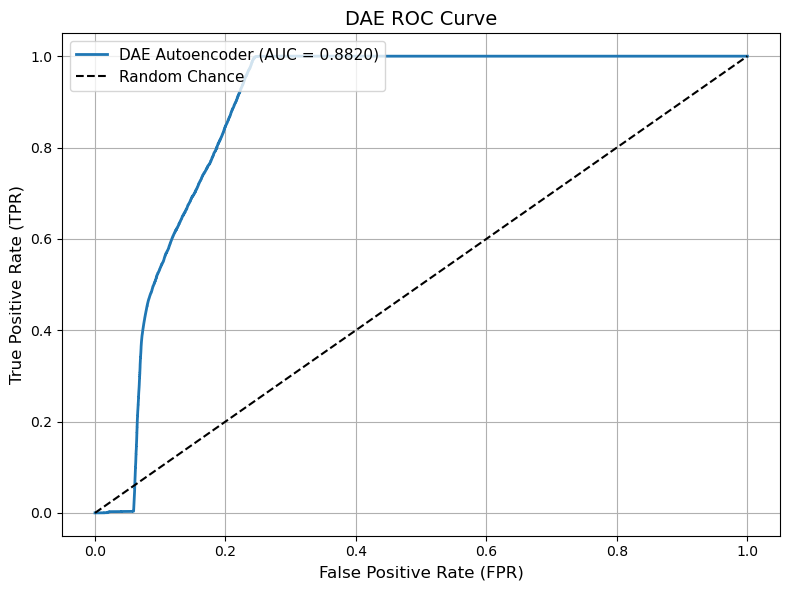

In [ ]:

# 1. Calculate False Positive Rate (FPR) and True Positive Rate (TPR)
# We use dae_scores because ROC curves require continuous scores/probabilities, not binary predictions.
fpr, tpr, thresholds = roc_curve(y_test_flat, dae_scores)
auc_score = roc_auc_score(y_test_flat, dae_scores)

# 2. Plotting configuration to match your image
plt.figure(figsize=(8, 6))

# Plot the DAE ROC curve
plt.plot(fpr, tpr, label=f'DAE Autoencoder (AUC = {auc_score:.4f})', color='tab:blue', linewidth=2)

# Plot the Random Chance diagonal line
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Random Chance')

# 3. Graph formatting (Labels, Title, Grid, Legend)
plt.title('DAE ROC Curve', fontsize=14)
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)

plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.grid(True)
plt.legend(loc='upper left', fontsize=11)

# 4. Display or Save the plot
plt.tight_layout()
plt.show()
# If running headless or on a remote server, uncomment the line below to save it instead:
# plt.savefig('dae_roc_curve.png', dpi=300)

--- Training VQ-VAE ---
Epoch 1/30 Train Loss: 1.8447 Val Loss: 906.1031
Epoch 2/30 Train Loss: 1.4510 Val Loss: 1043.1759
Epoch 3/30 Train Loss: 0.5324 Val Loss: 1010.2020
Epoch 4/30 Train Loss: 0.4602 Val Loss: 895.5097
Epoch 5/30 Train Loss: 0.3785 Val Loss: 843.1545
Epoch 6/30 Train Loss: 0.3425 Val Loss: 844.0341
Epoch 7/30 Train Loss: 0.3589 Val Loss: 1016.0763
Epoch 8/30 Train Loss: 0.3758 Val Loss: 995.6774
Epoch 9/30 Train Loss: 0.4389 Val Loss: 892.9059
Epoch 10/30 Train Loss: 0.3958 Val Loss: 1033.0963
Epoch 11/30 Train Loss: 0.3601 Val Loss: 1021.0363
Epoch 12/30 Train Loss: 0.3360 Val Loss: 1029.9049
Epoch 13/30 Train Loss: 0.3174 Val Loss: 1025.1198
Epoch 14/30 Train Loss: 0.3595 Val Loss: 1023.0755
Epoch 15/30 Train Loss: 0.3681 Val Loss: 1035.6355
Epoch 16/30 Train Loss: 0.3608 Val Loss: 1036.1826
Epoch 17/30 Train Loss: 0.3589 Val Loss: 1034.7633
Epoch 18/30 Train Loss: 0.3587 Val Loss: 1067.3347
Epoch 19/30 Train Loss: 0.4593 Val Loss: 822.3688
Epoch 20/30 Train Loss:

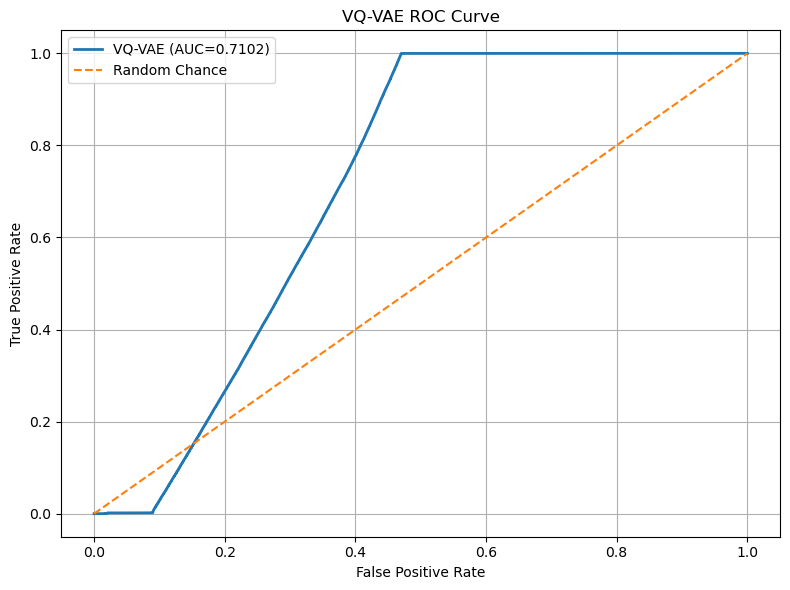

In [ ]:
num_features = train_X.shape[1] 

flat_labels = test_Y.cpu().numpy().flatten()
# Execution routines
model = VQVAE(input_dim=num_features)
model = VQVAE(input_dim=num_features)

test_scores, preds, threshold, auc = train_and_test_vqvae(model, train_loader, val_loader, loader, val_Y_numpy, flat_labels, num_features, epochs=30
)

In [ ]:
# Extract parameters from your active workspace arrays
num_features = train_X.shape[1] 

GAE_Model = GraphAutoencoder(num_features)
# Execution routines
train_and_test_gae(GAE_Model, train_loader, val_loader, loader, val_Y_numpy, flat_labels, num_features, epochs=30)

--- Training Graph Autoencoder ---
Epoch 1/30, Loss: 15.8915
Epoch 2/30, Loss: 8.8510
Epoch 3/30, Loss: 9.6559
Epoch 4/30, Loss: 8.9889
Epoch 5/30, Loss: 8.7911
Epoch 6/30, Loss: 8.9503
Epoch 7/30, Loss: 8.9601
Epoch 8/30, Loss: 9.7577
Epoch 9/30, Loss: 10.6781
Epoch 10/30, Loss: 5.0707
Epoch 11/30, Loss: 6.3778
Epoch 12/30, Loss: 6.0041
Epoch 13/30, Loss: 5.7700
Epoch 14/30, Loss: 4.9457
Epoch 15/30, Loss: 4.7766
Epoch 16/30, Loss: 3.1734
Epoch 17/30, Loss: 2.7713
Epoch 18/30, Loss: 2.7274
Epoch 19/30, Loss: 2.2761
Epoch 20/30, Loss: 5.3309
Epoch 21/30, Loss: 0.7147
Epoch 22/30, Loss: 0.7136
Epoch 23/30, Loss: 1.3466
Epoch 24/30, Loss: 0.7039
Epoch 25/30, Loss: 0.7125
Epoch 26/30, Loss: 0.7069
Epoch 27/30, Loss: 1.3050
Epoch 28/30, Loss: 0.7058
Epoch 29/30, Loss: 0.7059
Epoch 30/30, Loss: 0.9775
Best Threshold: 167.596713
Validation F1: 0.0099
GAE ROC-AUC: 0.8571
              precision    recall  f1-score   support

           0       0.99      0.98      0.99    269049
           1  

(array([167.22699, 167.19948, 167.19954, ..., 102.47011, 102.47011,
        102.33861], dtype=float32),
 array([0, 0, 0, ..., 0, 0, 0]),
 167.59671344642408,
 0.857105118594353)

In [ ]:
# improved_deep_model = DenoisingTabularAutoencoder(input_dim=train_X.shape[1])
# train_and_optimize_threshold(improved_deep_model,train_loader)

In [ ]:
rnn_model = AERNN(46572, train_X.shape[1], 256 , 8)
# model.apply(bias_init)
# model = model.to(device)

optimizer = torch.optim.RMSprop(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

In [ ]:
# 1. Initialize model with seq_len = 1 for your tabular row inputs
rnn_model = AERNN(seq_len=1, n_features=train_X.shape[1], latent_dim=256, hidden_size=8)

# 2. Correct the optimizer to target rnn_model
optimizer = torch.optim.Adam(rnn_model.parameters(), lr=5e-3)
loss_fn = nn.MSELoss()

num_epochs = 30
print("Starting AERNN Training Loop...")

for epoch in range(num_epochs):
    rnn_model.train()
    train_loss = 0
    
    for batch in train_loader:
        x = batch[0] # Shape: (batch_size, n_features)
        
        # Reshape 2D tabular data to 3D sequential data: (batch_size, 1, n_features)
        x_seq = x.unsqueeze(1)
        
        optimizer.zero_grad()
        recon = rnn_model(x_seq)
        
        # Compute loss across all dimensions/features
        loss = loss_fn(recon, x_seq)
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(rnn_model.parameters(), max_norm=1.0)
        optimizer.step()
        
        train_loss += loss.item()
        
    print(f"Epoch {epoch+1}/{num_epochs}, Avg Loss: {train_loss / len(train_loader):.4f}")

Starting AERNN Training Loop...
Epoch 1/30, Avg Loss: 0.2059
Epoch 2/30, Avg Loss: 0.1213
Epoch 3/30, Avg Loss: 0.0774
Epoch 4/30, Avg Loss: 0.0575
Epoch 5/30, Avg Loss: 0.0436
Epoch 6/30, Avg Loss: 0.0381
Epoch 7/30, Avg Loss: 0.0362
Epoch 8/30, Avg Loss: 0.0345
Epoch 9/30, Avg Loss: 0.0303
Epoch 10/30, Avg Loss: 0.0258
Epoch 11/30, Avg Loss: 0.0253
Epoch 12/30, Avg Loss: 0.0235
Epoch 13/30, Avg Loss: 0.0235
Epoch 14/30, Avg Loss: 0.0286
Epoch 15/30, Avg Loss: 0.0220
Epoch 16/30, Avg Loss: 0.0208
Epoch 17/30, Avg Loss: 0.0172
Epoch 18/30, Avg Loss: 0.0341
Epoch 19/30, Avg Loss: 0.0290
Epoch 20/30, Avg Loss: 0.0216
Epoch 21/30, Avg Loss: 0.0305
Epoch 22/30, Avg Loss: 0.0289
Epoch 23/30, Avg Loss: 0.0322
Epoch 24/30, Avg Loss: 0.0289
Epoch 25/30, Avg Loss: 0.0368
Epoch 26/30, Avg Loss: 0.0376
Epoch 27/30, Avg Loss: 0.0329
Epoch 28/30, Avg Loss: 0.0361
Epoch 29/30, Avg Loss: 0.0177
Epoch 30/30, Avg Loss: 0.0329


In [ ]:
train_X

tensor([[-0.4497, -0.1221, -0.3616,  ..., -0.0670, -0.0492, -1.0839],
        [-0.4545, -0.1202, -0.4359,  ..., -0.0670, -0.0492, -1.0839],
        [-0.4253,  0.0929, -0.4299,  ...,  0.0141, -0.0492, -1.0839],
        ...,
        [-0.4555, -0.1163, -0.4371,  ..., -0.0670, -0.0462, -0.3169],
        [-0.3930, -0.1171, -0.4383,  ..., -0.0670, -0.0462,  0.2544],
        [-0.4497, -0.1225, -0.3616,  ..., -0.0670, -0.0492,  2.6103]])

In [ ]:
def get_rnn_scores(model, loader, device):

    model.eval()

    scores = []

    with torch.no_grad():

        for batch in loader:

            x = batch[0].to(device)

            # Add sequence dimension
            x_seq = x.unsqueeze(1)

            recon = model(x_seq)

            # Reconstruction error per sample
            loss = F.mse_loss(
                recon,
                x_seq,
                reduction="none"
            ).sum(dim=-1).squeeze(-1)


            scores.extend(
                loss.cpu().numpy()
            )


    return np.asarray(scores)



# ==========================================
# Generate validation scores
# ==========================================

val_anomaly_scores = get_rnn_scores(
    rnn_model,
    val_loader,
    device
)


# Convert validation labels
if hasattr(val_Y, "cpu"):
    val_labels = val_Y.cpu().numpy().ravel().astype(int)
else:
    val_labels = np.asarray(val_Y).ravel().astype(int)



# ==========================================
# Find optimal threshold using validation set
# ==========================================

best_threshold = None
best_f1 = -1


thresholds = np.linspace(
    val_anomaly_scores.min(),
    val_anomaly_scores.max(),
    500
)


for threshold in thresholds:

    val_preds = (
        val_anomaly_scores >= threshold
    ).astype(int)


    score = f1_score(
        val_labels,
        val_preds,
        zero_division=0
    )


    if score > best_f1:
        best_f1 = score
        best_threshold = threshold



print(
    f"Best Validation Threshold: {best_threshold:.6f}"
)

print(
    f"Best Validation F1: {best_f1:.4f}"
)



# ==========================================
# Evaluate on Test Set
# ==========================================

test_anomaly_scores = get_rnn_scores(
    rnn_model,
    eval_loader,
    device
)


# Convert test labels
if hasattr(test_Y, "cpu"):
    test_labels = test_Y.cpu().numpy().ravel().astype(int)
else:
    test_labels = np.asarray(test_Y).ravel().astype(int)



# Apply frozen threshold
test_predictions = (
    test_anomaly_scores >= best_threshold
).astype(int)



# ==========================================
# Final Metrics
# ==========================================

auc = roc_auc_score(
    test_labels,
    test_anomaly_scores
)


print("\n--- AERNN Results ---")

print(
    f"ROC-AUC: {auc:.4f}"
)


print(
    classification_report(
        test_labels,
        test_predictions,
        zero_division=0
    )
)


print(
    f"Mean Reconstruction Error: {test_anomaly_scores.mean():.6f}"
)


Best Validation Threshold: 1.416044
Best Validation F1: 0.0031

--- AERNN Results ---
ROC-AUC: 0.8530
              precision    recall  f1-score   support

           0       0.98      0.98      0.98    269049
           1       0.00      0.00      0.00      5219

    accuracy                           0.96    274268
   macro avg       0.49      0.49      0.49    274268
weighted avg       0.96      0.96      0.96    274268

Mean Reconstruction Error: 0.197309


In [ ]:
# --- Update your dataset definitions ---
# Include both the features (data_X) and ground truth labels (data_Y)
# Change this line:
# data_Y = torch.tensor(data_y.values, dtype=torch.float32)

# # To this (flattens the 2D column into a clean 1D array):
# data_Y = torch.tensor(data_y.values, dtype=torch.float32).squeeze()
# eval_dataset = TensorDataset(data_X, data_Y)

# # Re-create your evaluation loader using the updated dataset
# eval_loader = DataLoader(eval_dataset, batch_size=512, shuffle=False)

In [ ]:
# import os
import time
import matplotlib.pyplot as plt
import seaborn as sns
import torch

def plot_loss_moment(losses):
    if not losses:
        print("No losses to plot.")
        return
    fig, ax = plt.subplots(figsize=(16, 9), dpi=80)
    ax.plot(losses, 'blue', label='train', linewidth=1)
    ax.set_title('Loss change in training')
    ax.set_ylabel('Loss')
    ax.set_xlabel('Iteration')
    ax.legend(loc='upper right')
    # Use a fallback if cf or cf.image_dir isn't defined in this scope
    # save_dir = cf.image_dir if 'cf' in globals() else '.'
    # plt.savefig(os.path.join(save_dir, 'loss_dagmm.png'))
    plt.close(fig)

# Model initialization
compressor = CompressNet(train_X.shape[1], 256, 128, 64, 32)
estimator = EstimateNet(34, 512, hyper_params.dropout_p, 2, hyper_params.lam1, hyper_params.lam2)

losses = []
loss_plot_interval = 20
steps = 0
loss_total = 0

compressor_opt = torch.optim.Adam(compressor.parameters(), lr=1e-3, amsgrad=True)
estimator_opt = torch.optim.Adam(estimator.parameters(), lr=1e-3, amsgrad=True)

print("Starting training debug run...")

# --- RESTRUCTURED TRAINING LOOP ---
for i in range(hyper_params.epoch_num):
    for batch in train_loader: # Using 'loader' as per your traceback line 86
        x = batch[0]  
        steps += 1

        # Forward Pass
        z, x_hat = compressor(x)
        loss = compressor.reconstruct_error(x, x_hat)

        gamma = estimator(z)
        loss += estimator.energy(gamma, z)
        loss_total += loss.detach().item()

        # Backward Pass & Optimization
        compressor_opt.zero_grad()
        estimator_opt.zero_grad()

        loss.backward()
        
        # Gradient clipping to ensure numerical safety
        torch.nn.utils.clip_grad_norm_(compressor.parameters(), max_norm=5.0)
        torch.nn.utils.clip_grad_norm_(estimator.parameters(), max_norm=5.0)
        
        compressor_opt.step()
        estimator_opt.step()

        if steps % loss_plot_interval == 0:
            print(f'Epoch: {i}  step: {steps}  loss: {loss_total/loss_plot_interval:.4f}')
            losses.append(loss_total / loss_plot_interval)
            loss_total = 0

Starting training debug run...
Epoch: 0  step: 20  loss: 41.7736
Epoch: 0  step: 40  loss: 1.5768
Epoch: 0  step: 60  loss: -2.5976
Epoch: 0  step: 80  loss: -2.4754
Epoch: 0  step: 100  loss: -3.7698
Epoch: 0  step: 120  loss: -5.3113
Epoch: 0  step: 140  loss: 6.7964
Epoch: 0  step: 160  loss: -3.7490
Epoch: 0  step: 180  loss: 4.7504
Epoch: 0  step: 200  loss: 0.4923
Epoch: 0  step: 220  loss: -1.9903
Epoch: 0  step: 240  loss: -4.2579
Epoch: 0  step: 260  loss: -4.9529
Epoch: 0  step: 280  loss: -4.9656
Epoch: 0  step: 300  loss: -4.3371
Epoch: 0  step: 320  loss: -2.9441
Epoch: 0  step: 340  loss: -3.5346
Epoch: 0  step: 360  loss: -3.5528
Epoch: 0  step: 380  loss: -1.5124
Epoch: 0  step: 400  loss: -3.5286
Epoch: 0  step: 420  loss: -2.9227
Epoch: 0  step: 440  loss: -2.9813
Epoch: 0  step: 460  loss: -3.5263
Epoch: 0  step: 480  loss: -3.4066
Epoch: 0  step: 500  loss: -2.8416
Epoch: 0  step: 520  loss: -1.8588
Epoch: 0  step: 540  loss: -0.7060
Epoch: 0  step: 560  loss: -1.00

In [ ]:

compressor.eval()
estimator.eval()

all_scores = []


with torch.no_grad():

    for batch in eval_loader:

        # Data only (no labels in loader)
        x = batch[0].to(device)


        # Encode input
        z, _ = compressor(x)


        # Mixture estimation
        gamma = estimator(z)

        m_prob = estimator.mixture_prob(gamma)
        m_mean = estimator.mixture_mean(gamma, z)
        m_cov = estimator.mixture_covar(
            gamma,
            z,
            m_mean
        )


        N, D = z.shape


        log_energies = torch.zeros(
            (N, estimator.mixture_dim),
            device=z.device
        )


        for k in range(estimator.mixture_dim):

            # Covariance determinant
            _, logdet = torch.linalg.slogdet(
                m_cov[k]
            )


            # Inverse covariance
            inv_cov = torch.linalg.pinv(
                m_cov[k]
            )


            # Mahalanobis distance
            diff = z - m_mean[k]

            mahalanobis = torch.sum(
                torch.matmul(diff, inv_cov) * diff,
                dim=1
            )


            # Gaussian log density
            log_density = -0.5 * (
                D * np.log(2 * np.pi)
                + logdet
                + mahalanobis
            )


            # Weighted mixture probability
            log_energies[:, k] = (
                torch.log(
                    m_prob[k] + 1e-8
                )
                + log_density
            )


        # DAGMM energy score
        batch_scores = (
            -torch.logsumexp(
                log_energies,
                dim=1
            )
            .cpu()
            .numpy()
        )


        all_scores.append(batch_scores)



# Combine all batches
final_scores = np.concatenate(all_scores)



# ==========================================
# Prepare Test Labels
# ==========================================

if hasattr(test_Y, "cpu"):

    final_labels = (
        test_Y
        .cpu()
        .numpy()
        .flatten()
        .astype(int)
    )

else:

    final_labels = (
        np.asarray(test_Y)
        .flatten()
        .astype(int)
    )



# ==========================================
# Apply Validation Threshold
# ==========================================

final_preds = (
    final_scores >= threshold
).astype(int)



# ==========================================
# Metrics
# ==========================================

print("================ DAGMM RESULTS ================")


print(
    "Label Distribution:",
    np.unique(
        final_labels,
        return_counts=True
    )
)


print(
    "Prediction Distribution:",
    np.unique(
        final_preds,
        return_counts=True
    )
)


print("\nClassification Report:")
print(
    classification_report(
        final_labels,
        final_preds,
        zero_division=0
    )
)


auc = roc_auc_score(
    final_labels,
    final_scores
)


print(
    f"\nROC-AUC Score: {auc:.4f}"
)


print(
    f"Mean Energy Score: {final_scores.mean():.6f}")

================ DAGMM RESULTS ================
Label Distribution: (array([0, 1]), array([269049,   5219]))
Prediction Distribution: (array([0]), array([274268]))

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99    269049
           1       0.00      0.00      0.00      5219

    accuracy                           0.98    274268
   macro avg       0.49      0.50      0.50    274268
weighted avg       0.96      0.98      0.97    274268


ROC-AUC Score: 0.5173
Mean Energy Score: -67.002556


In [ ]:
all_labels = []
for batch in loader:
    if len(batch) > 1:
        all_labels.extend(batch[1].cpu().numpy())
    else:
        all_labels.extend(np.zeros(batch[0].size(0)))

unique, counts = np.unique(all_labels, return_counts=True)
print("Label distribution in evaluation loader:")
print(dict(zip(unique, counts)))

Label distribution in evaluation loader:
{0.0: 274268}


In [ ]:
nz = 100 # Size of the latent noise vector

generator_model = Generator(input_dim=nz, hidden_dim=128, output_dim=train_X.shape[1])
discriminator_model = Discriminator(input_dim=train_X.shape[1], hidden_dim=128)

# Re-setup Adam optimizers to point to the new parameters
optimizerD = torch.optim.Adam(discriminator_model.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizerG = torch.optim.Adam(generator_model.parameters(), lr=0.0002, betas=(0.5, 0.999))


In [ ]:
# Initialize the ``BCELoss`` function
criterion = nn.BCELoss()

# Create batch of latent vectors that we will use to visualize
#  the progression of the generator
# fixed_noise = torch.randn(64, nz, 1, 1, device=device)

# Establish convention for real and fake labels during training
real_label = 1.
fake_label = 0.
lr = 0.0001

# Setup Adam optimizers for both G and D
optimizerD = torch.optim.Adam(discriminator_model.parameters(), lr=lr)
optimizerG = torch.optim.Adam(generator_model.parameters(), lr=lr)

In [ ]:
nz = 100


In [ ]:
import torch
import torch.nn as nn


def train_gan_anomaly_detector(
    netG,
    netD,
    train_loader,
    epochs,
    device,
    latent_dim=100
):

    netG = netG.to(device)
    netD = netD.to(device)


    criterion = nn.BCELoss()


    optimizerD = torch.optim.Adam(
        netD.parameters(),
        lr=0.0002,
        betas=(0.5, 0.999)
    )


    optimizerG = torch.optim.Adam(
        netG.parameters(),
        lr=0.0002,
        betas=(0.5, 0.999)
    )


    G_losses = []
    D_losses = []


    print("Starting GAN anomaly detection training...")


    for epoch in range(epochs):

        for batch in train_loader:

            # ================================
            # Real normal samples
            # ================================

            real = batch[0].to(device)

            batch_size = real.size(0)


            real_labels = torch.ones(
                batch_size,
                device=device
            )

            fake_labels = torch.zeros(
                batch_size,
                device=device
            )


            # ================================
            # Train Discriminator
            # ================================

            netD.zero_grad()


            # Real normal traffic
            output_real = netD(real).view(-1)


            loss_real = criterion(
                output_real,
                real_labels
            )


            # Generate fake normal-like traffic
            noise = torch.randn(
                batch_size,
                latent_dim,
                device=device
            )


            fake = netG(noise)


            output_fake = netD(
                fake.detach()
            ).view(-1)


            loss_fake = criterion(
                output_fake,
                fake_labels
            )


            loss_D = loss_real + loss_fake


            loss_D.backward()

            optimizerD.step()



            # ================================
            # Train Generator
            # ================================

            netG.zero_grad()


            output_fake = netD(fake).view(-1)


            # Generator wants discriminator
            # to classify generated samples as real

            loss_G = criterion(
                output_fake,
                real_labels
            )


            loss_G.backward()

            optimizerG.step()



            G_losses.append(
                loss_G.item()
            )

            D_losses.append(
                loss_D.item()
            )


        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"D Loss: {loss_D.item():.4f} "
            f"G Loss: {loss_G.item():.4f}"
        )


    return netG, netD, G_losses, D_losses

In [ ]:
netD = Discriminator(input_dim=8)
netG = Generator(100,hidden_dim=256,output_dim=8)

In [ ]:
netG, netD, G_losses, D_losses = train_gan_anomaly_detector(
    netG,
    netD,
    train_loader,
    epochs=50,
    device=device,
    latent_dim=100
)

Starting GAN anomaly detection training...
Epoch [1/50] D Loss: 1.0036 G Loss: 0.9737
Epoch [2/50] D Loss: 0.9050 G Loss: 1.0776
Epoch [3/50] D Loss: 0.9238 G Loss: 1.0900
Epoch [4/50] D Loss: 0.8569 G Loss: 1.2497
Epoch [5/50] D Loss: 0.9050 G Loss: 1.2138
Epoch [6/50] D Loss: 0.8298 G Loss: 1.3513
Epoch [7/50] D Loss: 0.9213 G Loss: 1.1183
Epoch [8/50] D Loss: 0.9167 G Loss: 1.1476
Epoch [9/50] D Loss: 0.8994 G Loss: 1.2230
Epoch [10/50] D Loss: 0.8474 G Loss: 1.3147
Epoch [11/50] D Loss: 0.8320 G Loss: 1.3758
Epoch [12/50] D Loss: 0.8608 G Loss: 1.5341
Epoch [13/50] D Loss: 0.8934 G Loss: 1.3480
Epoch [14/50] D Loss: 0.8929 G Loss: 1.3250
Epoch [15/50] D Loss: 0.9113 G Loss: 1.1905
Epoch [16/50] D Loss: 0.8094 G Loss: 1.5723
Epoch [17/50] D Loss: 0.9278 G Loss: 1.1865
Epoch [18/50] D Loss: 0.9149 G Loss: 1.1963
Epoch [19/50] D Loss: 0.8688 G Loss: 1.4476
Epoch [20/50] D Loss: 0.8653 G Loss: 1.2908
Epoch [21/50] D Loss: 0.8165 G Loss: 1.4006
Epoch [22/50] D Loss: 0.9153 G Loss: 1.105

In [ ]:
import torch
import numpy as np
from sklearn.metrics import (
    roc_auc_score,
    precision_recall_fscore_support,
    classification_report,
    f1_score
)


def get_anomaly_scores(discriminator_model, loader, device="cpu"):
    """
    Generates anomaly scores from discriminator.
    
    Assumption:
        Discriminator output:
        High value = normal
        Low value = anomaly
        
    Therefore:
        anomaly_score = 1 - discriminator_output
    """

    discriminator_model.eval()

    scores = []

    with torch.no_grad():

        for batch in loader:

            x = batch[0].to(device)

            outputs = discriminator_model(x).view(-1)

            # Convert normal probability into anomaly score
            anomaly_scores = 1.0 - outputs

            scores.extend(
                anomaly_scores.cpu().numpy()
            )

    return np.asarray(scores)



def find_best_threshold(scores, labels):
    """
    Finds threshold using validation data only.
    """

    best_threshold = None
    best_f1 = -1


    thresholds = np.linspace(
        scores.min(),
        scores.max(),
        500
    )


    for threshold in thresholds:

        predictions = (
            scores >= threshold
        ).astype(int)


        f1 = f1_score(
            labels,
            predictions,
            zero_division=0
        )


        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold


    return best_threshold, best_f1



def evaluate_anomaly_detector(
    discriminator_model,
    val_loader,
    val_Y,
    test_loader,
    test_Y,
    device="cpu"
):

    discriminator_model = discriminator_model.to(device)


    # ==========================================
    # Validation Phase (Threshold Selection)
    # ==========================================

    val_scores = get_anomaly_scores(
        discriminator_model,
        val_loader,
        device
    )


    if hasattr(val_Y, "cpu"):
        val_labels = (
            val_Y.cpu()
            .numpy()
            .flatten()
            .astype(int)
        )
    else:
        val_labels = (
            np.asarray(val_Y)
            .flatten()
            .astype(int)
        )


    threshold, val_f1 = find_best_threshold(
        val_scores,
        val_labels
    )


    print(
        f"Best Validation Threshold: {threshold:.6f}"
    )

    print(
        f"Validation F1: {val_f1:.4f}"
    )



    # ==========================================
    # Test Phase
    # ==========================================

    test_scores = get_anomaly_scores(
        discriminator_model,
        test_loader,
        device
    )


    if hasattr(test_Y, "cpu"):
        test_labels = (
            test_Y.cpu()
            .numpy()
            .flatten()
            .astype(int)
        )
    else:
        test_labels = (
            np.asarray(test_Y)
            .flatten()
            .astype(int)
        )


    # Apply validation threshold
    predictions = (
        test_scores >= threshold
    ).astype(int)



    # ==========================================
    # Metrics
    # ==========================================

    auc_score = roc_auc_score(
        test_labels,
        test_scores
    )


    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            test_labels,
            predictions,
            average="binary",
            zero_division=0
        )
    )


    print("\n=== Semi-Supervised Evaluation Results ===")

    print(
        f"ROC-AUC Score: {auc_score:.4f}"
    )

    print(
        f"Precision: {precision:.4f}"
    )

    print(
        f"Recall:    {recall:.4f}"
    )

    print(
        f"F1-Score:  {f1:.4f}"
    )


    print("\nClassification Report:")
    print(
        classification_report(
            test_labels,
            predictions,
            target_names=[
                "Normal",
                "Anomaly"
            ],
            zero_division=0
        )
    )


    return {
        "auc": auc_score,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "threshold": threshold,
        "scores": test_scores,
        "labels": test_labels
    }

In [ ]:
# X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
# y_test_tensor = torch.tensor(y_test, dtype=torch.long)  # Or float32 depending on loss, long is standard for labels
# test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# # 3. Re-run your loader creation from before
# test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)

In [ ]:
# 3. Pass THIS new loader into your evaluation function
results = evaluate_anomaly_detector(discriminator_model,val_loader,val_Y, eval_loader,test_Y, device="cpu")

Best Validation Threshold: 0.498249
Validation F1: 0.0277

=== Semi-Supervised Evaluation Results ===
ROC-AUC Score: 0.8214
Precision: 0.0565
Recall:    0.1060
F1-Score:  0.0737

Classification Report:
              precision    recall  f1-score   support

      Normal       0.98      0.97      0.97    269049
     Anomaly       0.06      0.11      0.07      5219

    accuracy                           0.95    274268
   macro avg       0.52      0.54      0.52    274268
weighted avg       0.96      0.95      0.96    274268



In [ ]:
# Assuming your test data loader returns (features, true_labels)
# where true_labels uses 0 for normal and 1 for attacks
# from torch.utils.data import DataLoader

# # Create the test_loader (adjust batch_size to match your training configuration)
# # test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)

# # Now run the evaluation function
# # results = evaluate_anomaly_detector(discriminator_model, loader, device="cpu")

# results = evaluate_anomaly_detector(discriminator_model, loader, device="cpu")

In [ ]:
import sklearn.svm
from sklearn.linear_model import SGDOneClassSVM
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,f1_score,classification_report

# train_X, test_X, train_Y, test_Y = train_test_split(data_X.numpy(),data_Y.numpy(),test_size=0.2)

scaler = StandardScaler()
train_x_values = scaler.fit_transform(train_X)
test_x_values = scaler.transform(test_X)
val_x_values = scaler.transform(val_X)

model = SGDOneClassSVM(
    nu=0.05,
    random_state=42
)
print(train_X)
print()
model.fit(train_x_values)
val_scores = -model.decision_function(val_x_values)

predictions = -model.decision_function(test_x_values)
predictions
# f1_score(test_Y,predictions)
mapped_predictions = np.where(predictions == -1, 1, 0)

# Now evaluate safely
# from sklearn.metrics import classification_report

print(classification_report(test_Y, mapped_predictions))
print("\nAUC Score:\n",roc_auc_score(test_Y, predictions))


tensor([[-0.4497, -0.1221, -0.3616,  ..., -0.0670, -0.0492, -1.0839],
        [-0.4545, -0.1202, -0.4359,  ..., -0.0670, -0.0492, -1.0839],
        [-0.4253,  0.0929, -0.4299,  ...,  0.0141, -0.0492, -1.0839],
        ...,
        [-0.4555, -0.1163, -0.4371,  ..., -0.0670, -0.0462, -0.3169],
        [-0.3930, -0.1171, -0.4383,  ..., -0.0670, -0.0462,  0.2544],
        [-0.4497, -0.1225, -0.3616,  ..., -0.0670, -0.0492,  2.6103]])



/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


              precision    recall  f1-score   support

         0.0       0.98      1.00      0.99    269049
         1.0       0.00      0.00      0.00      5219

    accuracy                           0.98    274268
   macro avg       0.49      0.50      0.50    274268
weighted avg       0.96      0.98      0.97    274268


AUC Score:
 0.08542433483990584


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
